# 1) Importing Libraries 

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from adjustText import adjust_text 

import warnings
warnings.filterwarnings("ignore")

# 2) Data Quality Assessment 

> ### **2.1.** Importing Dataset

In [37]:
df = pd.read_csv("eighteen_nineteen_university_datasets.csv", encoding="unicode_escape")
Data = pd.DataFrame(df)
display(Data.head(10))

,World Rank,Institution,Location,National Rank,Quality of Education,Alumni Employment,Quality of Faculty,Research Output,Quality Publications,Influence,Citations,Score
0,1,Harvard University,USA,1,2,1,1,1,1,1,1,100.0
1,2,Stanford University,USA,2,10,3,2,10,4,3,2,96.7
2,3,Massachusetts Institute of Technology,USA,3,3,11,3,30,15,2,6,95.1
3,4,University of Cambridge,United Kingdom,1,5,19,6,12,8,6,19,94.0
4,5,University of Oxford,United Kingdom,2,9,25,10,9,5,7,4,93.2
5,6,"University of California, Berkeley",USA,4,7,52,5,18,12,4,8,92.5
6,7,Princeton University,USA,5,4,15,4,146,99,28,27,91.9
7,8,Columbia University,USA,6,16,13,8,20,14,10,10,91.4
8,9,California Institute of Technology,USA,7,1,200,7,127,81,13,31,91.0
9,10,University of Chicago,USA,8,13,22,9,39,22,18,10,90.6


> ### **2.2.** Preliminary data analysis

In [38]:
print(f"\n The shape of the dataset is: \n\n {Data.shape}")


 The shape of the dataset is: 

 (1000, 12)


In [39]:
total_cells = Data.shape[0] * Data.shape[1]               # counting total number of cells in the DataFrame 
                                                          # counting total number of rows and columns in the DataFrame

print(f"\n The total number of cells in the dataset is: \n\n {total_cells}")


 The total number of cells in the dataset is: 

 12000


In [40]:
print(f" The features of the dataset are: \n ")

for col in Data.columns:
    print(repr(col))

 The features of the dataset are: 
 
'World Rank'
'Institution'
'Location'
'National Rank'
'Quality\xa0of Education'
'Alumni Employment'
'Quality\xa0of Faculty'
'Research Output'
'Quality Publications'
'Influence'
'Citations'
'Score'


> #### We can see that two of the features contain unusual characters, "Quality\xa0of Education", "Quality\xa0of Faculty",  let's remove them right now so they don't cause us problems later on.

In [41]:
Data.columns = Data.columns.str.replace('Quality\xa0of Education', 'Quality of Education', regex=False)
Data.columns = Data.columns.str.replace('Quality\xa0of Faculty', 'Quality of Faculty', regex=False)

print(f" The features of the dataset are: \n ")

for col in Data.columns:
    print(repr(col))

 The features of the dataset are: 
 
'World Rank'
'Institution'
'Location'
'National Rank'
'Quality of Education'
'Alumni Employment'
'Quality of Faculty'
'Research Output'
'Quality Publications'
'Influence'
'Citations'
'Score'


In [42]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   World Rank            1000 non-null   int64  
 1   Institution           1000 non-null   object 
 2   Location              1000 non-null   object 
 3   National Rank         1000 non-null   int64  
 4   Quality of Education  1000 non-null   object 
 5   Alumni Employment     1000 non-null   object 
 6   Quality of Faculty    1000 non-null   object 
 7   Research Output       1000 non-null   object 
 8   Quality Publications  1000 non-null   object 
 9   Influence             1000 non-null   object 
 10  Citations             1000 non-null   object 
 11  Score                 1000 non-null   float64
dtypes: float64(1), int64(2), object(9)
memory usage: 93.9+ KB


In [43]:
print(f"The unique values of the dataset are: \n\n{Data.nunique()}")

The unique values of the dataset are: 

World Rank              1000
Institution             1000
Location                  61
National Rank            213
Quality of Education     404
Alumni Employment        492
Quality of Faculty       221
Research Output          905
Quality Publications     892
Influence                830
Citations                 75
Score                    195
dtype: int64


In [44]:
print(f"Duplicate values in the dataset are: \n\n{Data.duplicated().sum()}")

Duplicate values in the dataset are: 

0


In [45]:
print(f" Descriptive statistics of the dataset are: \n\n")
Data.describe(include="all").T

 Descriptive statistics of the dataset are: 




,count,unique,top,freq,mean,std,min,25%,50%,75%,max
World Rank,1000.0,NaN,NaN,NaN,500.5,288.819436,1.0,250.75,500.5,750.25,1000.0
Institution,1000,1000,Harvard University,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,1000,61,USA,213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
National Rank,1000.0,NaN,NaN,NaN,40.023,49.22871,1.0,6.0,21.0,51.0,213.0
Quality of Education,1000,404,-,597,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Alumni Employment,1000,492,> 1000,509,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quality of Faculty,1000,221,-,731,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Research Output,1000,905,> 1000,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quality Publications,1000,892,> 1000,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Influence,1000,830,> 1000,171,NaN,NaN,NaN,NaN,NaN,NaN,NaN


> #### ●. "-" → We can say, it is effectively NaN, it contains no information. But at this Dataset, need for more study.
> #### ●. "> 1000" → It contains information, so converting it to NaN discards that data. It is better to model it using a threshold (e.g., 1001) or as an ordinal/censored variable.
> #### ●. The rate of missing_values across the features is highly uneven, in one case, it is due to a lack of measurement, while in the other, it stems from ranking limitations:
>> #### The "Quality of Faculty" and "Quality of Education" categories have missing_values ​​for more than half of the entries, whereas "Research Output," "Quality Publications," and "Influence" predominantly show "> 1000" rather than a missing_value indicator (such as "-"). This implies a fundamental difference between these two sets of variables regarding the reason for the absence of data.
> #### ●. "World Rank": Precisely 1 through 1,000, in order. This is effectively an index, not an analytical feature. We can use it as an index rather than a feature.
> #### ●. "National Rank": There is a significant gap—nearly a twofold difference—between the mean and the median for this feature; a few countries (such as the US, with 213 universities) create a "long tail" of high national rank values, whereas most countries have only a few universities, resulting in low national rankings.
>> #### In reality, this feature reflects "how many universities from a given country are on the list" more than it does absolute quality.
> #### ●. "Score": The range is 69.8 to 100, with a standard deviation of just 4.67—indicating low dispersion relative to the range. Competition at the very top is fierce and tightly packed, whereas the gaps in the middle range are smaller. 
> #### ●. "Location": 61 countries, the USA alone being the most frequent with 213 universities.
> #### ●. The features for "Quality of Education", "Alumni Employment", "Quality of Faculty", "Research Output", "Quality Publications", "Influence", and "Citations" were all read as objects (since they lack mean/std values).

In [46]:
# Total number of missing values in the DataFrame

total_missing = Data.isnull().sum().sum()
total_cells = Data.shape[0] * Data.shape[1]

missing_percent = (total_missing / total_cells) * 100

print(f"\nTotal number of missing values in the DataFrame are :")
print(f"\nTotal Missing Values -> {total_missing}")
print(f"\nMissing Percentage -> {missing_percent:.2f}%")


Total number of missing values in the DataFrame are :

Total Missing Values -> 0

Missing Percentage -> 0.00%


> #### As we saw, there are no missing_values. However, based on the description table, we must also examine the code in the following step for unusual data.

> ### **2.3.** Checking for unusual data

In [47]:
numeric_columns = ["National Rank","World Rank",
                    "Quality of Education",
                    "Alumni Employment",
                    "Quality of Faculty",
                    "Research Output",
                    "Quality Publications",
                    "Influence",
                    "Citations",
                    "Score"]

total_rows = len(Data)
report_rows = []

for col in numeric_columns:
    numeric_values = pd.to_numeric(Data[col], errors="coerce")

    mask = numeric_values.isna() & Data[col].notna()
    unknown_values = Data.loc[mask, col]

    if len(unknown_values) > 0:
        counts = unknown_values.value_counts()
        for value, count in counts.items():
            report_rows.append({
                "Feature": col,
                "Unusual Value": value,
                "Count": count,
                "Percentage (%)": round(count / total_rows * 100, 2)
            })

report = pd.DataFrame(report_rows)
report

,Feature,Unusual Value,Count,Percentage (%)
0,Quality of Education,-,597,59.7
1,Alumni Employment,> 1000,509,50.9
2,Quality of Faculty,-,731,73.1
3,Research Output,> 1000,77,7.7
4,Quality Publications,> 1000,51,5.1
5,Influence,> 1000,171,17.1
6,Citations,> 1000,110,11.0


> #### ●. As we have seen, there are no missing_values BUT, the fetures above contain some unusual data.
> #### ●. Unusual data ​​such as "-" and "> 1000" are not random errors or noise, they are part of the meaning of the ranking. A value of "-" indicates that no ranking was reported for that university in that index,meaning it can be said that the performance of that university in that index was not sufficient to record or report a specific numerical rank for it. And "> 1000" means that the university's ranking in that index was upper than 1000 and its exact rank has not been reported.

> #### ↓ The table below is taken directly from the official CWUR website for this data ↓

| Metric | Weight in CWUR |
|---|---|
| Quality of Education | 25% |
| Alumni Employment | 25% |
| Quality of Faculty | 10% |
| Research Output | 10% |
| Quality Publications | 10% |
| Influence | 10% |
| Citations | 10% |

**Source: [CWUR Methodology](https://cwur.org/methodology/world-university-rankings.php)**

> ### **2.4.** Testing and evaluation of unconventional data

> #### Now we need to test whether the "-" in the "Quality of Education" and "Quality of Faculty" features actually signifies "this university is poor," or if it is merely a nominal cutoff (meaning CWUR only displays the ranking up to a certain point and uses "-" for anything beyond that, regardless of the university's actual quality).

In [48]:
results = []

for col in ["Quality of Education", "Quality of Faculty"]:
    is_dash = Data[col].astype(str) == "-"

    results.append({
        "Feature": col,
        "Mean World Rank (with -)": Data.loc[is_dash, "World Rank"].mean(),
        "Mean World Rank (without -)": Data.loc[~is_dash, "World Rank"].mean(),
        "Best World Rank among - rows": Data.loc[is_dash, "World Rank"].min()
    })

comparison_table = pd.DataFrame(results)

top20 = Data[Data["World Rank"] <= 20]
top20_dash_count = (top20["Quality of Faculty"].astype(str) == "-").sum()

comparison_table

,Feature,Mean World Rank (with -),Mean World Rank (without -),Best World Rank among - rows
0,Quality of Education,618.415410,325.821340,22
1,Quality of Faculty,603.209302,221.390335,60


> #### ●. There is a significant difference in average World Rank (618 versus 326 for the "Education" category), indicating a genuine correlation between a "–" mark and a lower ranking, thus, it is not merely a random occurrence.
> #### ●. However, this correlation is not absolute, as a university ranked 22nd (along with a few others in the top 20) also received a "–" mark. Had there been a strict cutoff, this would not have happened.
> #### ●. Consequently, the hypothesis that a "-" represents a rare event/essentially a zero value (rather than necessarily reflecting the university's overall quality) appears logical.

> #### Question:
>> #### Can a "-" rating in the "Quality of Education" category be offset by the other criteria, or does it ruin the university's overall final score?

In [49]:
has_dash_edu = Data["Quality of Education"].astype(str) == "-"

score_comparison = pd.DataFrame([
    {
        "Group": "Universities (with -) in Education",
        "Mean Score": Data.loc[has_dash_edu, "Score"].mean()
    },
    {
        "Group": "Universities (without -) in Education",
        "Mean Score": Data.loc[~has_dash_edu, "Score"].mean()
    }
])

score_comparison

,Group,Mean Score
0,Universities (with -) in Education,73.034338
1,Universities (without -) in Education,77.997022


> #### ●. Based on the mean comparison:
>> #### The average score for entries marked with "-" (73.03) was indeed lower than for those without it (77.99) —> meaning that, generally, a "-" designation is associated with a lower score. This confirms that the "-" indicator represents a genuine negative impact rather than meaningless noise.
> #### ●. Based on the UCSF case study:
>> #### For the University of California, San Francisco (UCSF):
>>> #### It had a "-" designation for "Quality of Education."
>>> #### It also had a value of ">1000" (indicating very poor performance) for "Alumni Employment".
>>> #### However, it posted very strong figures across the four related metrics (Quality of Faculty, Research Output, Quality Publications, Influence, and Citations), resulting in a final score of 87.7—well above the dataset's overall average (75.03).
> #### ●. "-", it generally has a negative impact, as it typically leads to a drop in score. However, this effect is neither absolute nor irreversible.
>> #### A university can fully compensate for weak or missing_value in one or two criteria (even those with high weightings, such as Education (25%)) by performing strongly across the remaining criteria, thereby still securing a top-tier global ranking (e.g.  within the world's top 25).

> #### ↓ Review of a sample from a university ranked 22nd ↓

In [50]:
rank_22_case = Data[Data['World Rank'] == 22]
rank_22_case

,World Rank,Institution,Location,National Rank,Quality of Education,Alumni Employment,Quality of Faculty,Research Output,Quality Publications,Influence,Citations,Score
21,22,"University of California, San Francisco",USA,17,-,> 1000,13,45,23,8,17,87.7


> #### Having confirmed with a single case (University of California, San Francisco (UCSF)) that "-" in "Quality of Education" can be fully compensated by strength in other metrics, the next step was to check whether this pattern is a one-off exception or a recurring trend. 

> #### ↓ This code lists the top 20 highest-ranked universities that have "-" in this metric, sorted by "World Rank" ↓

In [51]:
dash_edu = Data[Data['Quality of Education'].astype(str) == '-']
dash_edu_ranked = dash_edu[['Institution', 'World Rank', 'Score']].sort_values('World Rank').head(20)
dash_edu_ranked

,Institution,World Rank,Score
21,"University of California, San Francisco",22,87.7
59,Seoul National University,60,83.7
79,Emory University,80,82.5
88,University of Texas MD Anderson Cancer Center,89,82.0
93,Baylor College of Medicine,94,81.8
102,National University of Singapore,103,81.4
105,Erasmus University Rotterdam,106,81.3
106,KU Leuven,107,81.2
113,Arizona State University,114,80.9
126,VU University Amsterdam,127,80.5


> #### ●. The 7 of 20 universities (35%) were specialized medical or graduate-level institutions (such as Baylor College of Medicine and MD Anderson Cancer Center), these institutions do not enroll undergraduates at all, so the "Quality of Education" criterion (which is measured based on the success of undergraduate alumni) is fundamentally inapplicable to them.
> #### ●. The 13 of 20 universities (65%) were prestigious comprehensive universities (e.g., Seoul National, Fudan, NUS, KU Leuven) that certainly do have undergraduate students, however, because the specific criterion in question (alumni winning a top-tier international award) is exceedingly rare, even these excellent universities scored zero.
> #### ●. After examining all the patterns, we conclude that: The "-" symbol indicates a temporary, remediable weakness in a very specific and rare metric, it signifies neither a data collection issue nor an overall weakness of the university.

> #### Consequently, for the final processing stage, we can replace it with **max_rank + 1** and a placeholder flag.

> ### **2.5.** Managing and handling unsual data

In [52]:
Data_Cleaned = Data.copy()

for col in report["Feature"].unique():
    raw_values = Data_Cleaned[col].astype("string")
    marker_mask = raw_values.isin(["-", "> 1000"])

    Data_Cleaned[f"{col}_was_placeholder"] = marker_mask.astype(int)

    numeric_values = pd.to_numeric(raw_values, errors="coerce").astype("float64")
    max_rank = numeric_values.max()
    numeric_values.loc[marker_mask] = max_rank + 1
    Data_Cleaned[col] = numeric_values

Data_Cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   World Rank                            1000 non-null   int64  
 1   Institution                           1000 non-null   object 
 2   Location                              1000 non-null   object 
 3   National Rank                         1000 non-null   int64  
 4   Quality of Education                  1000 non-null   float64
 5   Alumni Employment                     1000 non-null   float64
 6   Quality of Faculty                    1000 non-null   float64
 7   Research Output                       1000 non-null   float64
 8   Quality Publications                  1000 non-null   float64
 9   Influence                             1000 non-null   float64
 10  Citations                             1000 non-null   float64
 11  Score             

> #### ●. For columns containing "> 1000," replacing the value with "max + 1" makes perfect sense, as "> 1000" implies a rank worse than the highest observed value—a valid statistical inference.
> #### ●. However, the assumption differs slightly for columns containing "-". 
> #### ●. A "-" indicates that the metric was not measured or reported for that university, rather than necessarily implying the university holds the worst rank for that metric. By replacing "-" with "max + 1", we are assuming that missing data equates to the worst possible performance. This assumption may not hold true; these universities might simply not have been evaluated by CWUR for that specific metric, rather than having performed poorly.
> #### ●. Instead of simply converting "-" and "> 1000" to NaN and then dropping the entire row or column (which would result in significant data loss), this code replaces them with a logical numerical value (max_rank + 1). This ensures that all 1,000 universities remain in the dataset.
> #### ●. Columns that were stored as objects (strings) due to the presence of "-" or "> 1000" are now converted into actual numbers, enabling further statistical analysis or modeling. As long as these columns remain objects, they are effectively unusable for most machine learning models (with a few exceptions).
> #### ●. We create a new binary column to identify which rows lacked an actual value and contain an imputed or synthetic value instead. Each is 1 where the original value was "-" or "> 1000", and 0 otherwise.

> ### **2.6.** Reviewing dataset after handling the unusual data

In [53]:
# Duplicate_values in the Data_Cleaned
print(f"Duplicate values in the dataset are: {Data_Cleaned.duplicated().sum()}")


# Total number of missing values in the Data_Cleaned
total_missing = Data_Cleaned.isnull().sum().sum()
total_cells = Data_Cleaned.shape[0] * Data_Cleaned.shape[1]

missing_percent = (total_missing / total_cells) * 100

print(f"\nTotal number of missing values in the Data_Cleaned are : {total_missing} and the percentage of missing values is: {missing_percent:.2f}%")


# Description of the Data_Cleaned
print(f"\nDescriptive statistics of the dataset are: \n\n")
Data_Cleaned.describe(include="all").T

Duplicate values in the dataset are: 0

Total number of missing values in the Data_Cleaned are : 0 and the percentage of missing values is: 0.00%

Descriptive statistics of the dataset are: 




,count,unique,top,freq,mean,std,min,25%,50%,75%,max
World Rank,1000.0,NaN,NaN,NaN,500.5,288.819436,1.0,250.75,500.5,750.25,1000.0
Institution,1000,1000,Harvard University,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,1000,61,USA,213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
National Rank,1000.0,NaN,NaN,NaN,40.023,49.22871,1.0,6.0,21.0,51.0,213.0
Quality of Education,1000.0,NaN,NaN,NaN,528.532,208.781322,1.0,405.75,667.0,667.0,667.0
Alumni Employment,1000.0,NaN,NaN,NaN,725.001,342.466554,1.0,425.75,998.0,998.0,998.0
Quality of Faculty,1000.0,NaN,NaN,NaN,261.18,84.233419,1.0,282.75,304.0,304.0,304.0
Research Output,1000.0,NaN,NaN,NaN,508.454,300.080433,1.0,250.75,500.5,754.25,1001.0
Quality Publications,1000.0,NaN,NaN,NaN,502.85,292.595057,1.0,250.75,500.5,750.25,998.0
Influence,1000.0,NaN,NaN,NaN,528.643,321.668846,1.0,250.75,502.5,814.75,998.0


# 3) Features Understanding 

> ## **3.1.** The "raw form" of each feature

In [54]:
cols = ["Quality of Education", "Quality of Faculty", "Alumni Employment",
        "Research Output", "Quality Publications", "Influence", "Citations"]

palette = sns.color_palette("viridis", n_colors=len(cols))

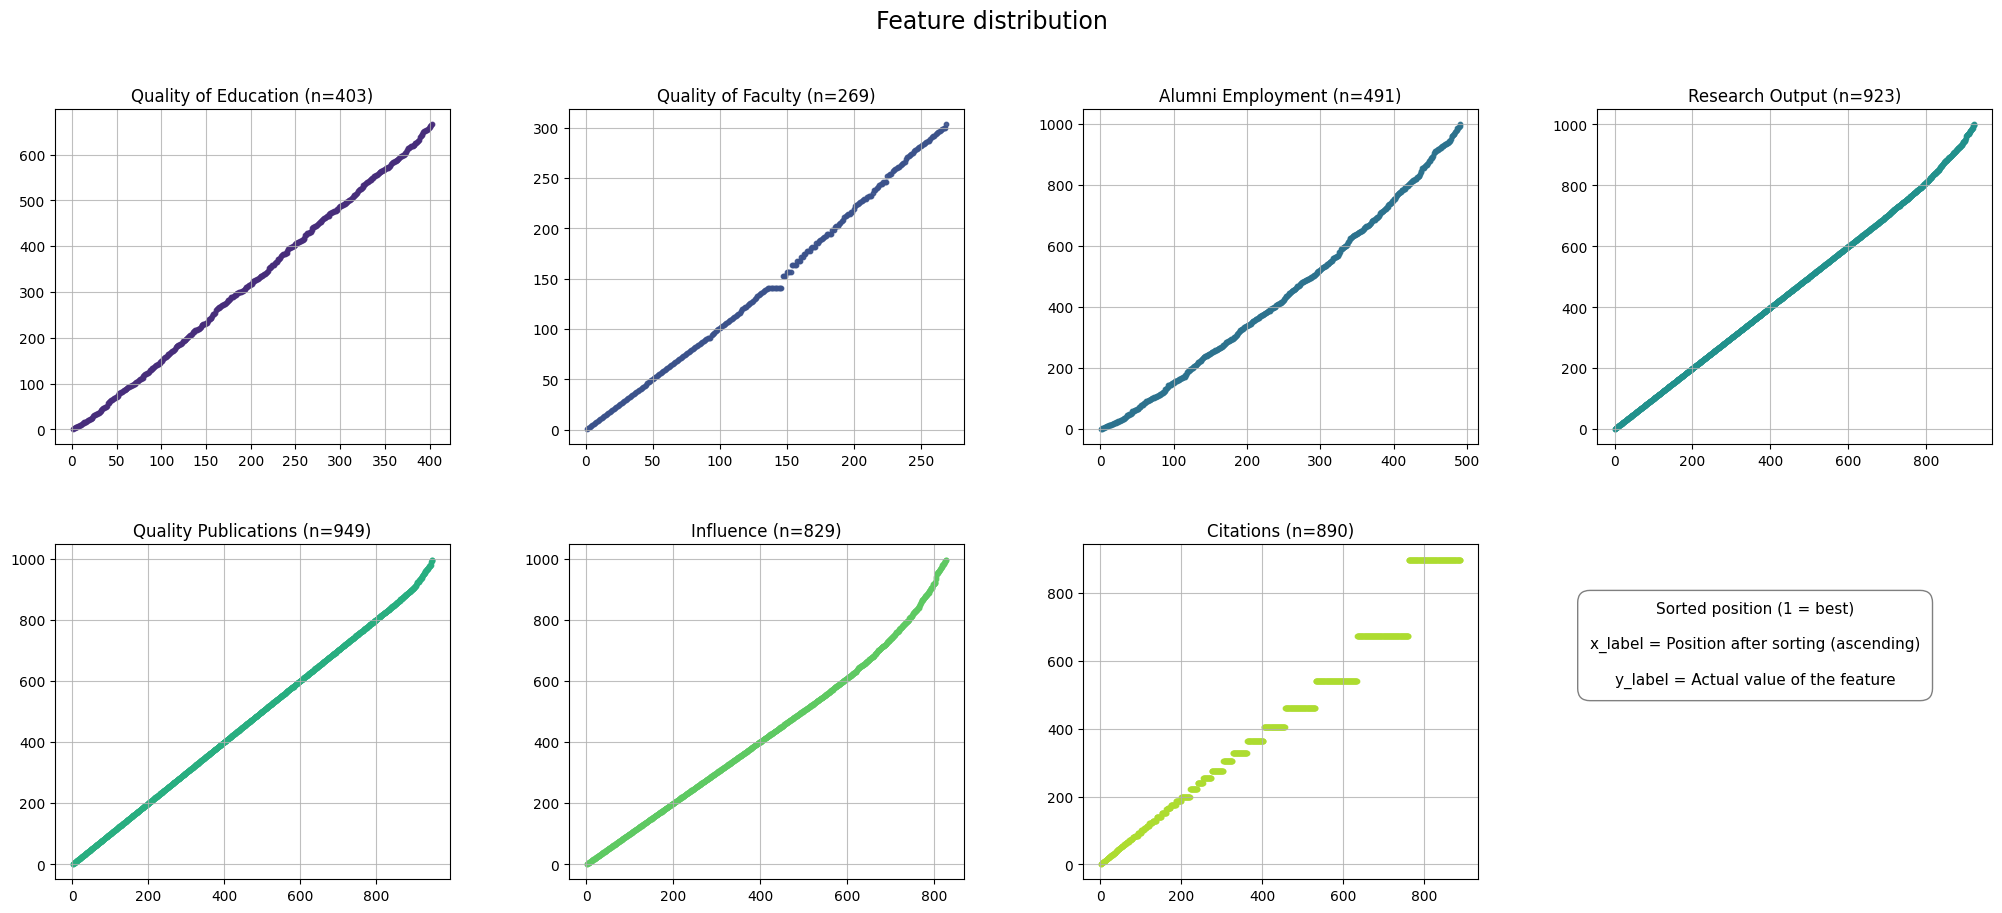

In [55]:
fig, axes = plt.subplots(2, 4, figsize=(25, 10))

axes = axes.flatten()

for i, col in enumerate(cols):
    flag = col + "_was_placeholder"
    real = Data_Cleaned[Data_Cleaned[flag] == 0][col].sort_values().reset_index(drop=True)                 # Flag == 0 -> The value is real 
                                                                                                           # Flag == 1 -> The value is placeholder

    ax = axes[i]
    ax.scatter(
        range(1, len(real) + 1), 
        real, 
        color=palette[i], 
        s=10, 
        alpha=0.9
        )
    ax.set_title(f"{col} (n={len(real)})")
    ax.grid(True, alpha=0.8)

axes[7].axis("off") 

axes[-1].text(
    0.4, 0.7,
    
    "Sorted position (1 = best)\n\n"
    "x_label = Position after sorting (ascending)\n\n"
    "y_label = Actual value of the feature",

    transform=axes[-1].transAxes,
    ha="center",
    va="center",
    fontsize=11,

    bbox=dict(
        boxstyle="round,pad=0.8",
        facecolor="white",
        edgecolor="gray"
    )
)

plt.subplots_adjust(
    hspace=0.3,
    wspace=0.3
)

plt.suptitle(
    "Feature distribution",
    fontsize=17,
    y=0.98
)

plt.show()

> #### ●. Six features "Quality of Education", "Alumni Employment", "Research Output", "Quality Publications", and "Influence", all exhibit a relatively uniform and continuous slope; in other words, their distributions are roughly uniform rather than clustered around a mean.
> #### ●. The "Quality of Faculty" shows a small step (near the 140–150 mark), indicating that several universities share nearly identical values—though this feature is quite subtle.
> #### ●. It is quite clear that "Citations" absolutely needs careful consideration. instead of a continuous line, it displays several large, distinct horizontal steps.

> ## **3.2.** Correlation of each feature with Score(Only on real values)

In [56]:
results = []

for col in cols:
    flag = col + "_was_placeholder"
    real = Data_Cleaned[Data_Cleaned[flag] == 0]
    corr = real[col].corr(real["Score"], method="spearman")
    results.append([col, len(real), round(corr, 3)])

corr_table = pd.DataFrame(results, columns=["Feature", "N_real", "Spearman_with_Score"])
corr_table = corr_table.sort_values("Spearman_with_Score")

corr_table

,Feature,N_real,Spearman_with_Score
4,Quality Publications,949,-0.959
5,Influence,829,-0.895
3,Research Output,923,-0.886
6,Citations,890,-0.854
1,Quality of Faculty,269,-0.714
0,Quality of Education,403,-0.503
2,Alumni Employment,491,-0.370


> #### **NOTE:** 
>> #### We calculate the correlation of each feature with the Score only based on the actual values ​​(rows where the flag is 0).

> #### ●. The correlation is all negative, because these columns are ranks: lower rank means better performance and higher Score
> #### ●. This comparison does not imply causation. Since the "Score" is likely derived from a combination of these very features, a high correlation was to be expected.
> #### ●. Each feature represents a ranking, indicating the university's global standing based on that specific criterion; a lower rank signifies a better position, while a higher Score corresponds to a better rank. 
> #### ●. The size of the number is important, not its sign, and a worse rank (a larger number) is usually associated with a lower score. A value close to 1 indicates a very strong relationship, whereas a value close to 0 indicates a weak one.
> #### ●. Both the National Rank and World Rank columns do not have independent information and are derived from Score.

> ## **3.3.** Score distribution for real and placeholder data

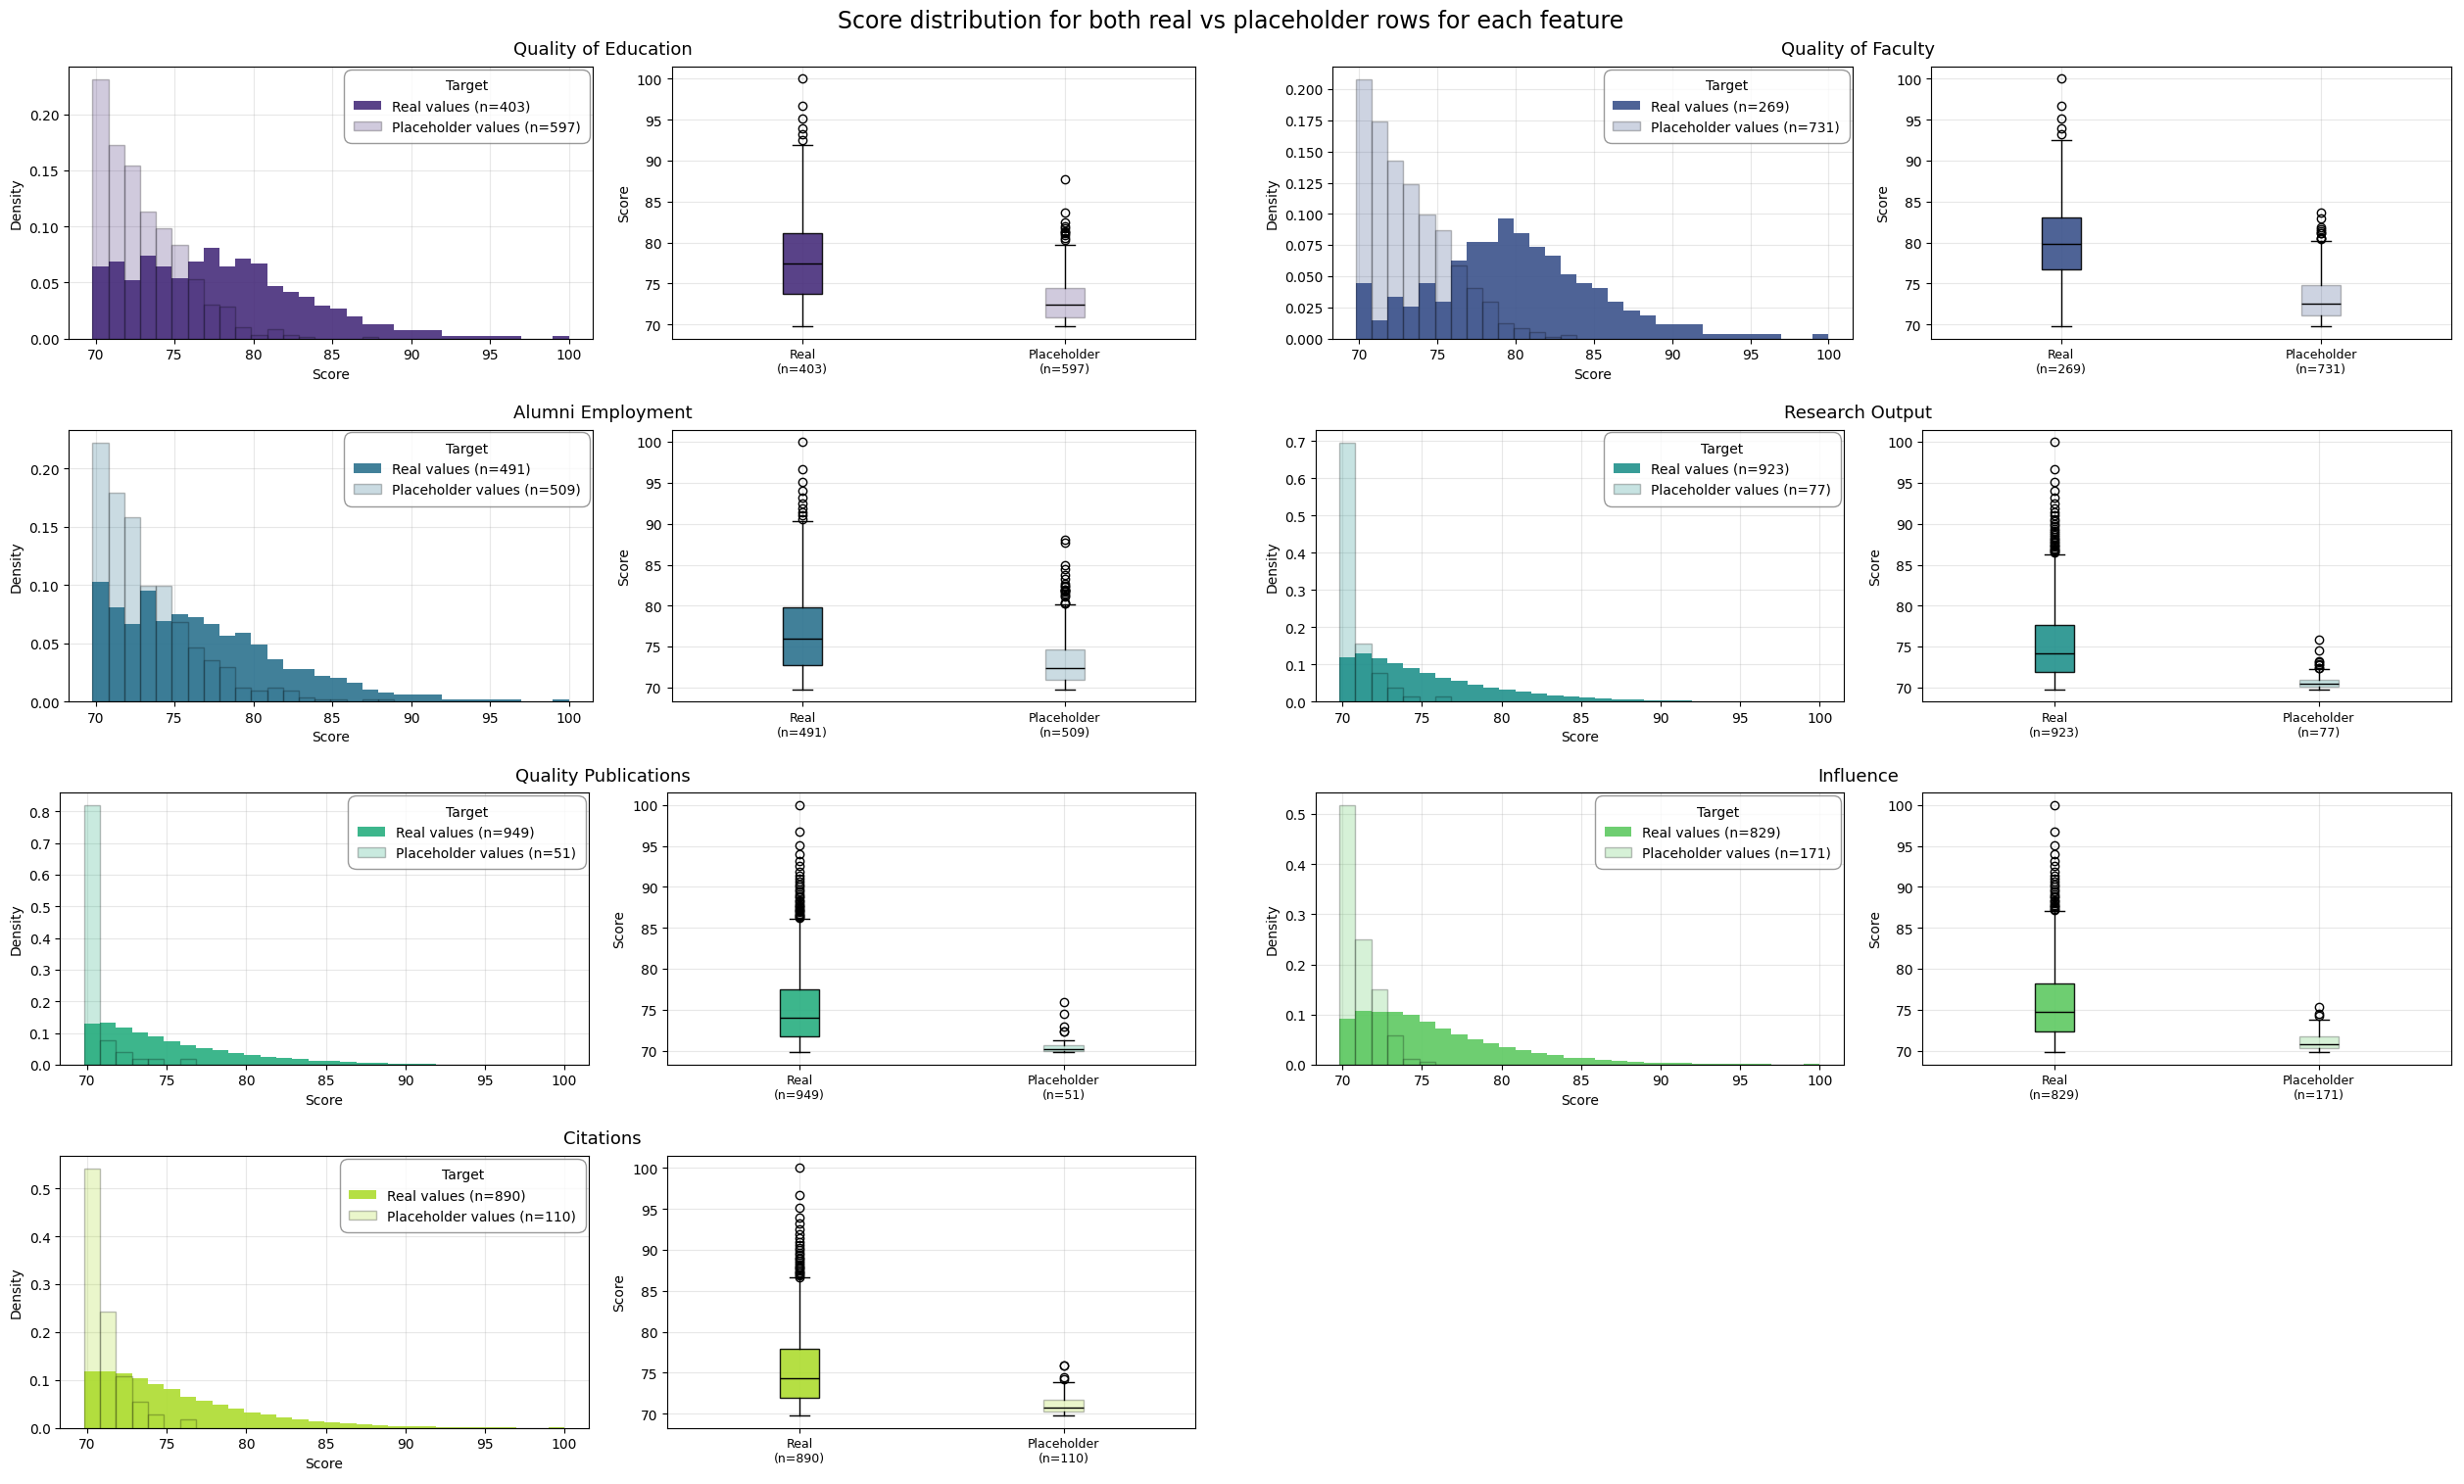

In [57]:
score_min = Data_Cleaned["Score"].min()
score_max = Data_Cleaned["Score"].max()

fig = plt.figure(figsize=(25, 15), layout="constrained")

subfigs = fig.subfigures(4, 2, wspace=0.05, hspace=0.04)

for i, col in enumerate(cols):

    row = i // 2
    column = i % 2
    subfig = subfigs[row, column]

    # Color for this feature
    feature_color = palette[i]

    flag = col + "_was_placeholder"

    real = Data_Cleaned[
        Data_Cleaned[flag] == 0
    ]["Score"]

    placeholder = Data_Cleaned[
        Data_Cleaned[flag] == 1
    ]["Score"]

    subfig.suptitle(
        col,
        fontsize=13
    )

    ax_hist, ax_box = subfig.subplots(1, 2)

    # Histogram
    ax_hist.hist(
        real,
        bins=30,
        range=(score_min, score_max),
        density=True,
        alpha=0.9,
        color=feature_color,
        label=f"Real values (n={len(real)})"
    )

    ax_hist.hist(
        placeholder,
        bins=30,
        range=(score_min, score_max),
        density=True,
        alpha=0.25,
        color=feature_color,
        edgecolor="#000000",
        linewidth=1,
        label=f"Placeholder values (n={len(placeholder)})"
    )

    ax_hist.set_xlabel("Score")
    ax_hist.set_ylabel("Density")

    ax_hist.grid(
        True,
        alpha=0.3
    )

    ax_hist.set_axisbelow(True)

    # Legend
    leg = ax_hist.legend(
        loc="best",
        fontsize=10,
        title="Target",
        frameon=True,
        edgecolor="gray",
    )

    leg.get_frame().set_boxstyle(
        "round",
        pad=0.3,
        rounding_size=0.6
    )

    # Boxplot
    bp = ax_box.boxplot(
        [real, placeholder],
        patch_artist=True,
        medianprops={"color": "black"}
    )

    bp["boxes"][0].set_facecolor(feature_color)
    bp["boxes"][1].set_facecolor(feature_color)
    bp["boxes"][0].set_alpha(0.9)
    bp["boxes"][1].set_alpha(0.25)

    ax_box.set_xticks([1, 2])

    ax_box.set_xticklabels(
        [
            "Real\n(n=" + str(len(real)) + ")",
            "Placeholder\n(n=" + str(len(placeholder)) + ")"
        ],
        fontsize=9
    )

    ax_box.set_ylabel("Score")

    ax_box.grid(
        True,
        alpha=0.3
    )

    ax_box.set_axisbelow(True)

fig.suptitle(
    "Score distribution for both real vs placeholder rows for each feature",
    fontsize=17,
)

plt.show()

> #### **NOTE**
>> #### We examine whether the "unsual data" are random or related to the score itself.
>> #### Our primary goal with this plot is to show the distribution of the two groups, rather than merely their counts, that is why density has been used.

> #### ●. "Quality of Faculty", "Quality of Education" and "Alumni Employment"
>> #### The orange box is wider and overlaps more with the blue one. This indicates that this group does not consist solely of "weak" institutions, it also includes strong universities that simply did not report data for this specific metric.
>> #### Thease columns, contain many placeholders (specifically, the "-" symbol), indicating that the metric was not reported for that university.
> #### ●. "Research Output", "Quality Publications", "Influence" and "Citations"
>> #### Thease columns, contain few placeholders (specifically, "> 1000"), indicating that the university's rank for that metric was lower than 1000.
>> #### The orange box is very narrow and positioned at the bottom of the range (near 70). These four categories show the least overlap with the blue ones. This makes sense, as these universities actually ranked lower than 1000.
> #### ●. Across all seven features, the histograms show the placeholder rows positioned at the lower end of the score distribution. In the box plots, the orange box sits below the blue one, and in the histograms, the orange distribution is concentrated toward the left (lower scores). So, an identical pattern is observed across the first three and the second four features, indicating that our unsual data are not random but rather contain their own specific information and characteristics.

> ## **3.4.** The correlation between the 7 features

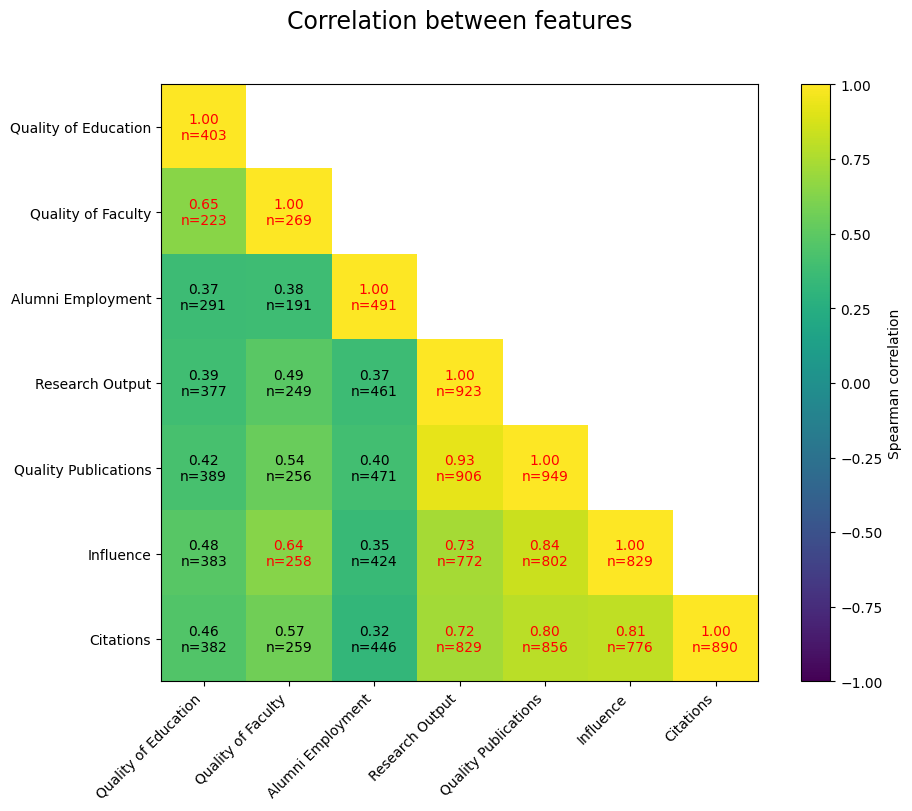

In [58]:
masked = Data_Cleaned[cols].copy()

for col in cols:
    flag = col + "_was_placeholder"
    masked.loc[Data_Cleaned[flag] == 1, col] = np.nan

corr = masked.corr(method="spearman")
corr = corr.mask(np.triu(np.ones_like(corr, dtype=bool), k=1))

notna = masked.notna().astype(int)
n_pairs = notna.T.dot(notna)

fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")

im = ax.imshow(
    corr,
    cmap="viridis",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticklabels(cols)

for i in range(len(cols)):
    for j in range(len(cols)):

        if j > i:
            continue

        value = corr.iloc[i, j]
        n = n_pairs.iloc[i, j]

        # for our greater strength of correlation
        color = "red" if abs(value) > 0.6 else "black"   

        ax.text(
            j, i,
            f"{value:.2f}\nn={n}",
            ha="center",
            va="center",
            color=color
        )

fig.colorbar(
    im,
    ax=ax,
    label="Spearman correlation"
)

plt.title(
    "Correlation between features",
    fontsize=17,
    y=1.08
)

plt.show()

> #### **NOTE**
>> #### Checking only on the actual values, along with the number of samples in each pair — to find features that give duplicate information
>> #### To prevent placeholders from skewing the correlation, we temporarily convert them to NaN.
>> #### The number of common rows where both columns have real values is also displayed alongside the correlation.
>> #### n= The number of rows where both columns had actual values.

> #### ●. The features "Research Output", "Quality Publications", "Influence" and "Citations" form a very strong cluster, their inter-correlations range from 0.72 to 0.93. These metrics largely reflect the same underlying signal. In this cluster, the sample sizes (n) are large; this means these strong correlations were calculated based on a large sample and are more reliable.
> #### ●. "Alumni Employment" and "Quality of Education" are the weakest indicators. Graduate performance does not necessarily align with research strength. This pair has the lowest (n), given this small sample size, the figure is prone to greater fluctuation compared to the other cells and should be interpreted with greater caution.
> #### ●. "Quality of Faculty" can be viewed as a connecting link between the weaker pair of indicators and the features of the strong cluster. This is likely because faculty quality impacts both education and research output.
> #### ●. The "Quality of Faculty" row and column consistently show a smaller "n" (ranging from 191 to 269), this is because the column itself contains only 269 actual values and the remaining data are placeholder, with the remainder consisting of imputed data. Consequently, any correlation involving this column is calculated based on a smaller subset.
> #### ●. In general, the row and column for "Quality of Faculty" consistently show a smaller (n), because this column contains only 269 actual values ​​(with a 73% flag rate). Consequently, any correlation involving this column is calculated based on a smaller subset.

> ## **3.5.** The actual nature of the relationship between these three pairs—observing

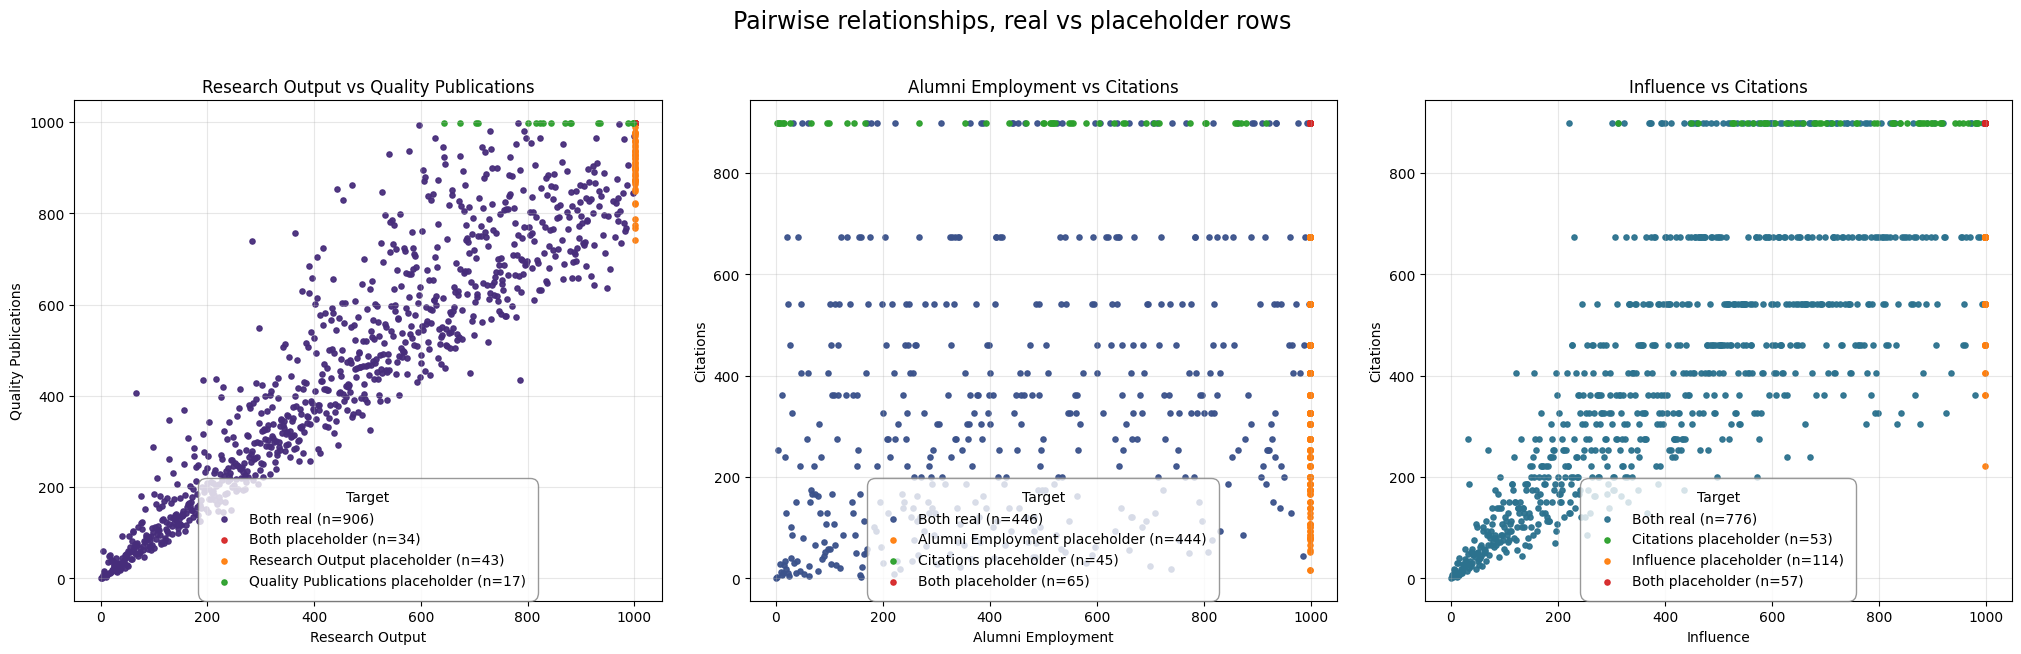

In [59]:
def category(df, col_x, col_y):
    flag_x = col_x + "_was_placeholder"
    flag_y = col_y + "_was_placeholder"

    x_ph = (
        df[flag_x] == 1
        if flag_x in df.columns
        else pd.Series(False, index=df.index)
    )

    y_ph = (
        df[flag_y] == 1
        if flag_y in df.columns
        else pd.Series(False, index=df.index)
    )

    cat = pd.Series("Both real", index=df.index)

    cat[x_ph & ~y_ph] = f"{col_x} placeholder"
    cat[~x_ph & y_ph] = f"{col_y} placeholder"
    cat[x_ph & y_ph] = "Both placeholder"

    return cat

fig, axes = plt.subplots(
    1, 3,
    figsize=(25, 6.5)
)

plt.subplots_adjust(
    hspace=0.3,
    wspace=0.15
)

pairs = [
    ("Research Output", "Quality Publications", axes[0]),
    ("Alumni Employment", "Citations", axes[1]),
    ("Influence", "Citations", axes[2]),
]

for i, (col_x, col_y, ax) in enumerate(pairs):

    cat = category(
        Data_Cleaned,
        col_x,
        col_y
    )

    real_color = palette[i]

    cmap = {
        "Both real": real_color,
        "Both placeholder": "tab:red"
    }

    cmap[f"{col_x} placeholder"] = "tab:orange"
    cmap[f"{col_y} placeholder"] = "tab:green"

    for label in cat.unique():

        sub = Data_Cleaned[cat == label]

        ax.scatter(
            sub[col_x],
            sub[col_y],
            s=14,
            alpha=0.95,
            color=cmap[label],
            label=f"{label} (n={len(sub)})"
        )

    ax.set_xlabel(col_x)
    ax.set_ylabel(col_y)

    ax.set_title(
        f"{col_x} vs {col_y}"
    )

    ax.grid(
        True,
        alpha=0.3
    )

    leg = ax.legend(
        loc="lower center",
        fontsize=10,
        title="Target",
        frameon=True,
        edgecolor="gray",
    )

    leg.get_frame().set_boxstyle(
        "round",
        pad=0.5,
        rounding_size=0.6
    )

fig.suptitle(
    "Pairwise relationships, real vs placeholder rows",
    fontsize=17,
    y=1.02
)

plt.show()

> #### **NOTE**
>> #### A closer examination (using scatterplots) of the actual nature of the relationship between these three pairs—observing whether the relationship is truly linear and clean or exhibits hidden patterns or outliers, and seeing where the placeholder rows for each pair fall within that relationship.
>> #### I wrote the real_pair function to keep only rows for each pair of columns that both have real values (not just one).
>> #### Strongest pair (Research Output–Quality Publications, correlation 0.93)
>> #### Weakest pair (Alumni Employment–Citations, correlation 0.32)
>> #### Middle overlap-ratio pair (Influence–Citations, correlation 0.81)

>  #### ●. "Research Output"–"Quality Publications"
>> #### There are no unusual outliers, but the dispersion is greater at the lower end of the rankings than at the top(Over 600). This means top-tier universities perform consistently across both metrics, whereas weaker universities might fare very poorly in one area while performing relatively better in the other.
>> #### The orange points have formed a vertical column on the right, near x=1000. The green points are at the top of the chart, forming a horizontal line near y=1000. The red points are exactly in the top-right corner because both attributes were simultaneously set to the placeholder value. This is entirely consistent with the "> 1000" logic.
> #### ●. "Alumni Employment"–"Citations" 
>> #### The plot resembles a series of parallel horizontal lines rather than a typical scatter cloud. This is not because the relationship is weak, but rather because the "Citations" column contains a high number of duplicate values.
>> #### The top rankings (from 1 to around 100) are almost entirely unique. however, as the rankings get lower, the number of universities sharing the exact same rank increases. This high frequency of shared ranks is particularly evident in the "Citations" category. It appears that the Citations ranking is derived from a rounded continuous score, and at the tail end of the distribution (among lower-ranked universities), many institutions have received identical scores.
>> #### The orange data points form a vertical column near x=1000, distributed across multiple horizontal levels of "Citations (real)". This indicates that even when "Alumni Employment" is unreported, "Citations" can take on any value (high or low), in other words, the two variables are independent—both in terms of their actual values ​​and their patterns of missingness.
> #### ●. "Influence"–"Citations" 
>> #### The relationship for the blue group is strong and relatively consistent. At the top rankings (below 200), the points are clustered very closely together; as the rank worsens, the dispersion increases.
>> #### The area where the orange and green points are scattered, No university with an unreported Influence score ranks better than approximately 200 in Citations, and no university with an unreported Citations score ranks better than approximately 300 in Influence. This indicates that having a "placeholder" status for one metric imposes a distinct ceiling on the quality of the other; in other words, there are no "elite" universities (those with very high rankings) where one of these two metrics is unreported.
>> #### The red one is stuck exactly in the top-right corner because both values ​​were replaced simultaneously.

> ## **3.6.** Multivariate outliers

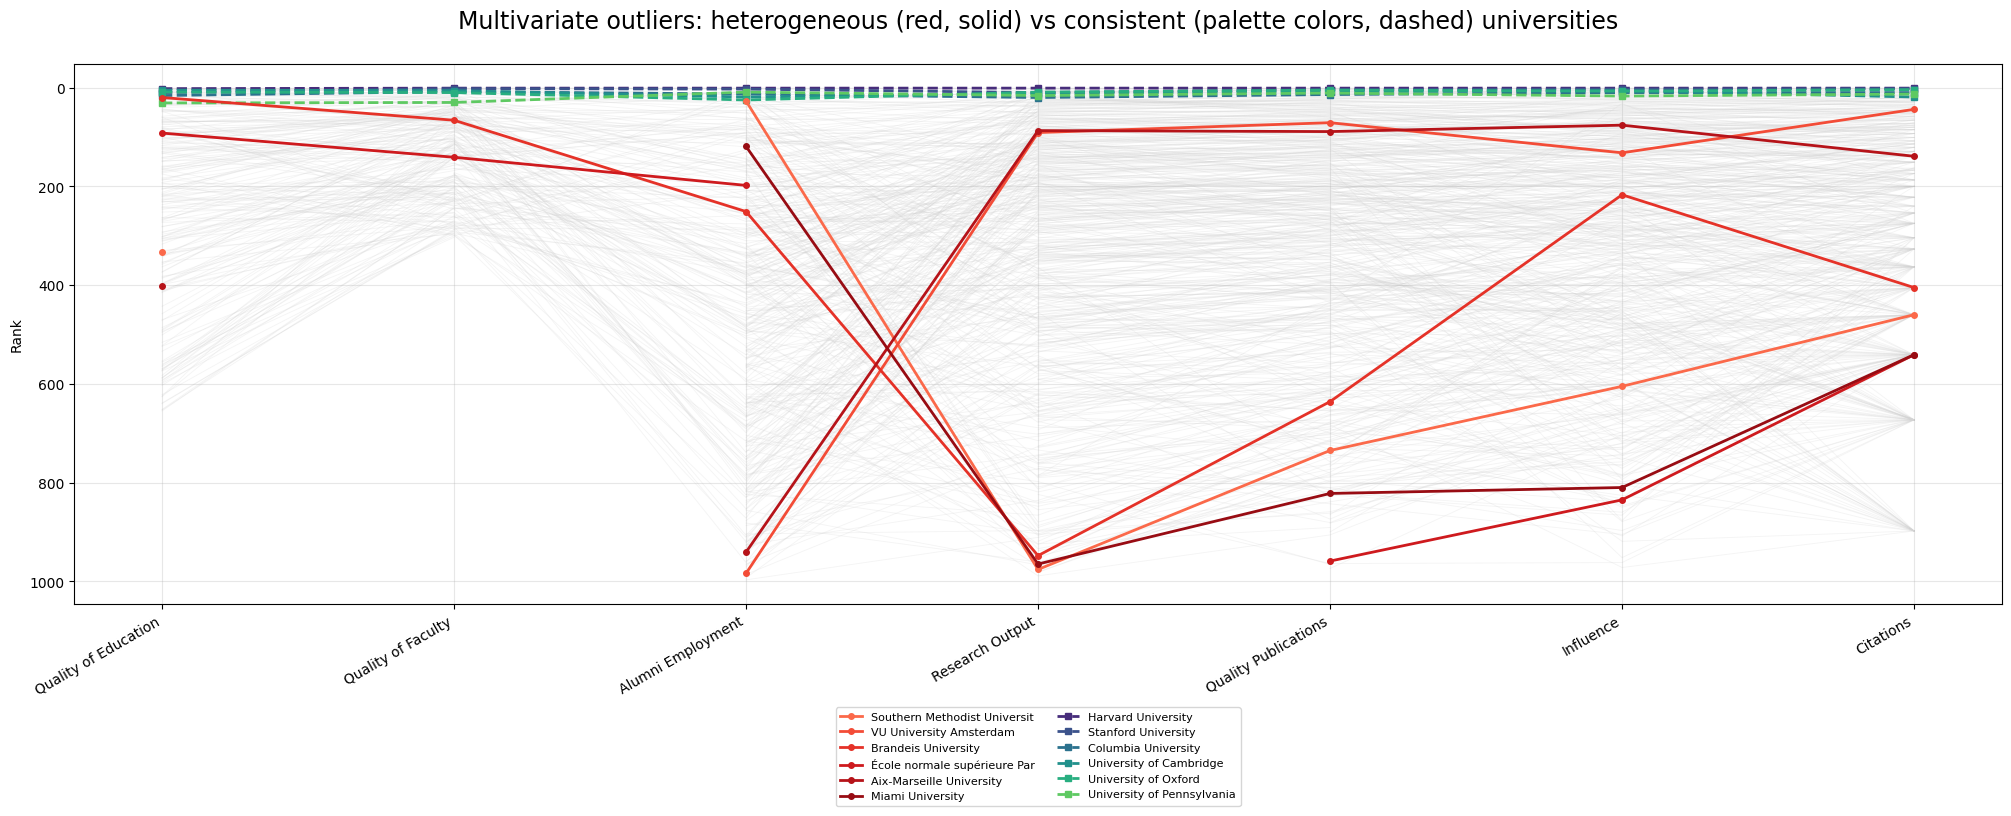

In [60]:
masked = Data_Cleaned[cols].copy()

for c in cols:
    masked.loc[
        Data_Cleaned[c + "_was_placeholder"] == 1,
        c
    ] = np.nan

n_real = masked.notna().sum(axis=1)
spread = masked.max(axis=1) - masked.min(axis=1)
std = masked.std(axis=1)

profile = pd.DataFrame({
    "Institution": Data_Cleaned["Institution"],
    "Location": Data_Cleaned["Location"],
    "Score": Data_Cleaned["Score"],
    "n_real": n_real,
    "spread": spread,
    "std": std,
})

ok = profile[
    profile["n_real"] >= 5
].copy()

heterogeneous = (
    ok.sort_values("spread", ascending=False)
      .head(6)
)

consistent = (
    ok.sort_values("spread", ascending=True)
      .head(6)
)

fig, ax = plt.subplots(
    figsize=(20, 8),
    layout="constrained"
)

x = range(len(cols))

for idx in ok.index:

    ax.plot(
        x,
        masked.loc[idx, cols],
        color="lightgray",
        alpha=0.25,
        linewidth=0.6,
        zorder=1
    )

colors_hetero = plt.cm.Reds(
    np.linspace(0.5, 0.9, len(heterogeneous))
)

for (idx, row), c in zip(
    heterogeneous.iterrows(),
    colors_hetero
):

    ax.plot(
        x,
        masked.loc[idx, cols],
        color=c,
        linewidth=2,
        marker="o",
        markersize=4,
        label=row["Institution"][:28],
        zorder=3
    )

colors_consist = palette[:len(consistent)]

for (idx, row), c in zip(
    consistent.iterrows(),
    colors_consist
):

    ax.plot(
        x,
        masked.loc[idx, cols],
        color=c,
        linewidth=2,
        linestyle="--",
        marker="s",
        markersize=4,
        label=row["Institution"][:28],
        zorder=2
    )

ax.set_xticks(x)

ax.set_xticklabels(
    cols,
    rotation=30,
    ha="right"
)

ax.invert_yaxis()

ax.set_ylabel("Rank")

ax.set_title(
    "Multivariate outliers: heterogeneous (red, solid) "
    "vs consistent (palette colors, dashed) universities",
    fontsize=17,
    y=1.05
)

ax.legend(
    fontsize=8,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2
)

ax.grid(
    True,
    alpha=0.3
)

plt.show()

> #### **NOTE** 
>> #### Real values only. lower/higher-on-plot = better
>> #### Systematically identifying universities that excel in one feature but perform very poorly in another—that is, a heterogeneous profile.
>> #### For each university, I retained only the actual values ​​of its seven features and calculated the spread between its best and worst rankings across those features. I considered only those universities with at least five actual feature values ​​to ensure the comparison was meaningful.
>> #### I didn't plot the placeholder values, because if I had included the substituted value "max + 1", any university with multiple flags would have appeared artificially heterogeneous.

> #### ●. The most heterogeneous universities (solid red line)

| University | Country | Score | Dispersion Range |
|----|----|----|----|
| Southern Methodist University | USA | 74.0 | 949 |
| VU University Amsterdam | Netherlands | 80.5 | 940 |
| Brandeis University | USA | 77.3 | 928 |
| École normale supérieure Paris-Saclay | France | 72.3 | 867 |
| Aix-Marseille University | France | 80.1 | 865 |

> #### They all perform very well in terms of "alumni employment" or "quality of education", but very poorly in "research output". In other words, these universities are strong in education/graduate employment, yet weak in raw scientific output.



> #### ●. The most homogeneous universities (blue dotted line)

| University | Score | Breadth | Dispersion |
|----|----|----|----|
| Harvard University | 100.0 | 1.0 |
| Stanford University | 96.7 | 8.0 |
| Columbia University | 91.4 | 12.0 |

> #### Harvard, Stanford, and Columbia rank close to 1 across virtually all seven features; their lines are nearly horizontal and hug the top of the chart. This confirms that their superiority is comprehensive, rather than being limited to just one or two metrics.

> ## **3.7.** Missing(Placeholder) data pattern by country

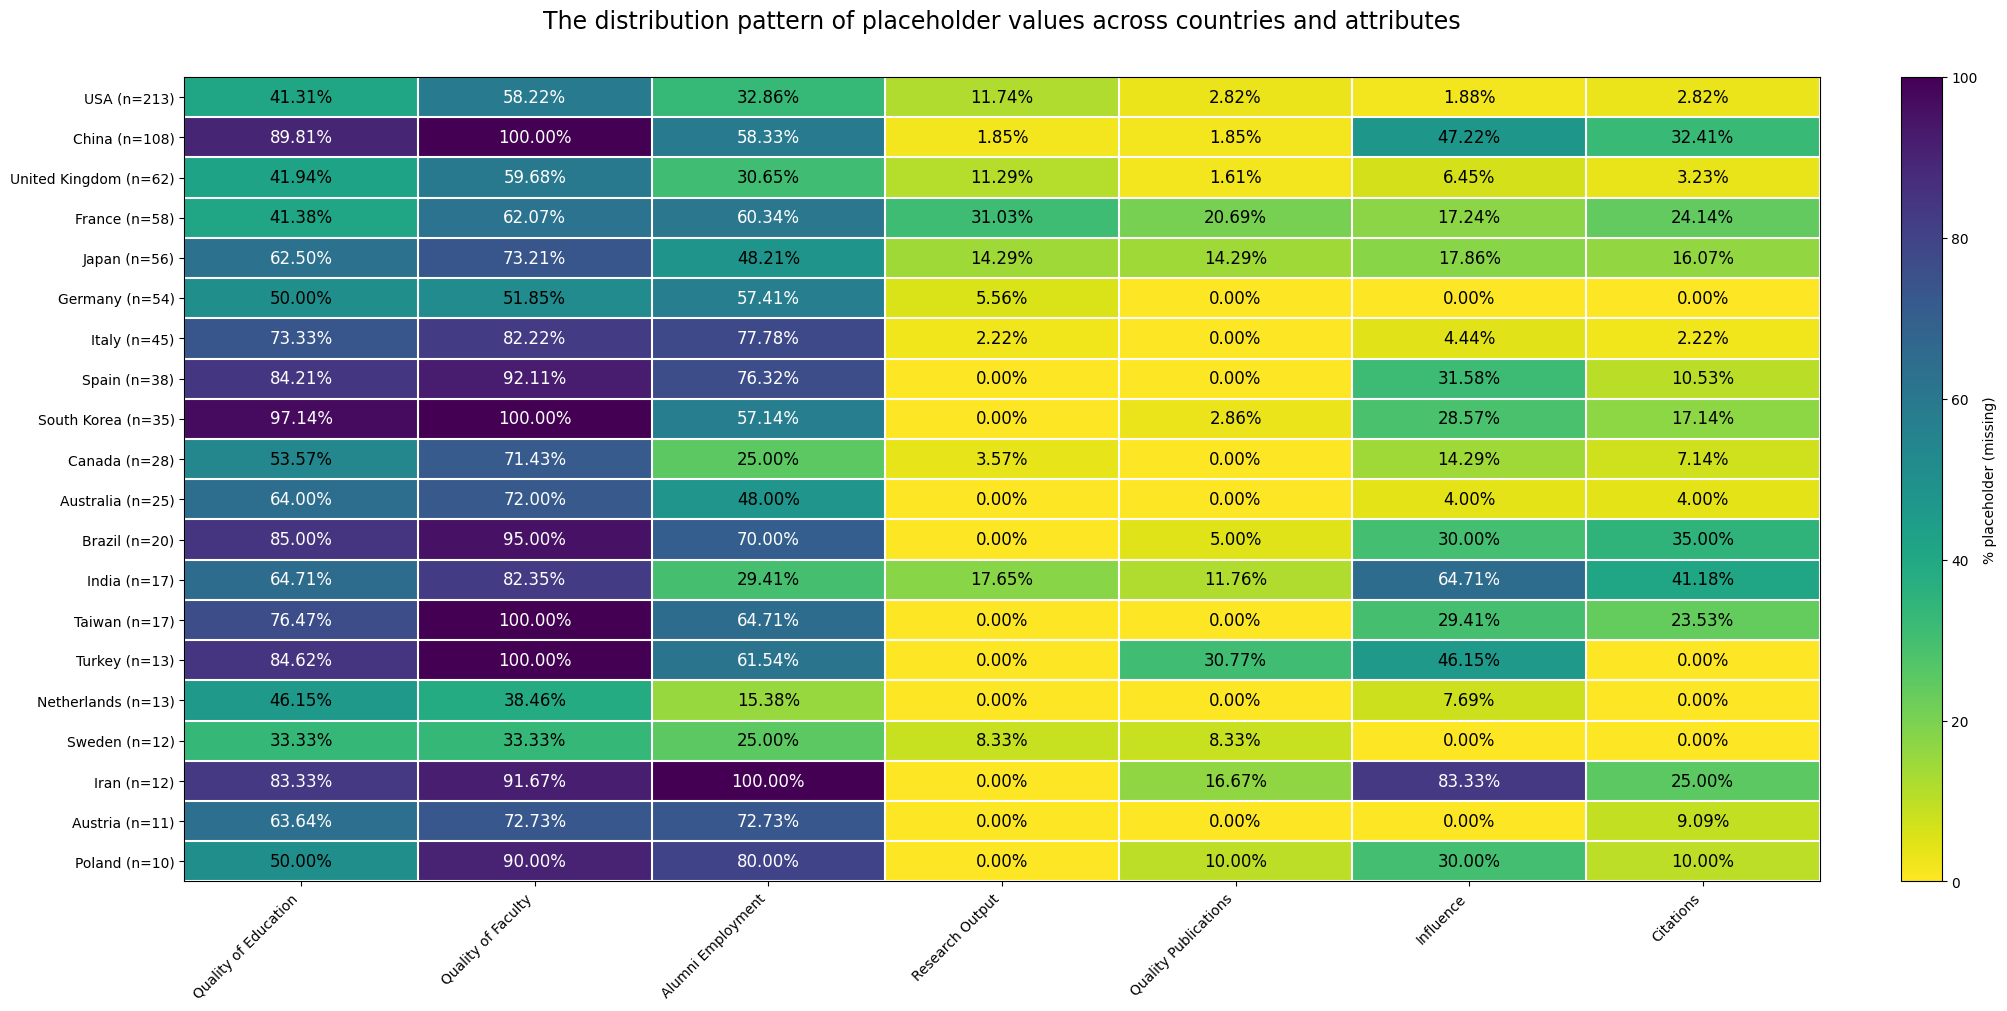

In [61]:
top_countries = Data_Cleaned["Location"].value_counts().head(20).index.tolist()

matrix = []
labels = []
for country in top_countries:
    sub = Data_Cleaned[Data_Cleaned["Location"] == country]
    labels.append(f"{country} (n={len(sub)})")
    row = [(sub[col + "_was_placeholder"] == 1).mean() * 100 for col in cols]
    matrix.append(row)

matrix = np.array(matrix)

fig, ax = plt.subplots(figsize=(20, 10), layout="constrained")

im = ax.imshow(
    matrix, 
    cmap="viridis_r", 
    vmin=0, 
    vmax=100, 
    aspect="auto"
    )

ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)

for i in range(len(labels)):
    for j in range(len(cols)):
        v = matrix[i, j]
        text_color = "white" if v > 55 else "black" 
        ax.text(j, i, f"{v:.2f}%", ha="center", va="center",
                color=text_color, fontsize=12)

ax.set_xticks(np.arange(-0.5, len(cols), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(labels), 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=1.5)
ax.tick_params(which="minor", length=0) 

fig.colorbar(im, ax=ax, label="% placeholder (missing)")
ax.set_title(
    "The distribution pattern of placeholder values ​​across countries and attributes",
    fontsize=17,
    y=1.05
    )

plt.show()

> #### **NOTE**
>> #### Does the pattern of missing data depend on the country? Have certain countries deliberately refrained from reporting specific data?
>> #### This chart does not directly measure university quality, country rankings, or data accuracy. rather, it illustrates the distribution pattern of placeholder values ​​across countries and attributes.
>> #### In terms of evidence, a 100% rate in a country with 3 rows is not the same as a 100% rate in a country with 300 rows.
>> #### The dataset covers 61 distinct countries, but 13 of them have only one university. Therefore, I focused on the 20 countries with the highest number of universities and calculated the placeholder percentage for all seven features for them.
>> #### For the sake of clarity, we refer to the three features "Quality of Faculty", "Quality of Education" and "Alumni Employment" ACADEMIC features and the four features "Research Output", "Quality Publications", "Influence" and "Citations" as RESEARCH features.

> #### ●. The Netherlands and Sweden are the most thorough countries in terms of reporting (with an average of approximately 15.30% for placeholders), while Iran (averaging approximately 57.15%) and China (averaging approximately 47.30%) are the countries with the highest rates of non-compliance.
> #### ●. Some columns are always dark:
>> #### The "Quality of Faculty", after that "Quality of Education" and "Alumni Employment" appears dark across almost all countries, this indicates that no country reports well on these three features.
> #### ●. Some columns are always light:
>> #### "Research Output" and "Quality Publications" almost always appear light (with values ​​close to zero), meaning that virtually all universities report on these two features. It has better data coverage.
> #### ●. Some countries have dark colors in most features, Iran, then China and South Korea. For China(with n=108), the rate for the "Faculty Quality" indicator is 100% (meaning no Chinese university reports this indicator); even more notable is the unusually high rate for the "Impact" (47%) and "Citations" (32%) indicators, whereas the corresponding figures for the United States are below 3%. This indicates that China's reporting is weaker not only in the "–" categories but also in the ">1000" categories.
> #### ●. "Quality of Faculty" is likely one of the most important factors to examine regarding the data generation or compilation process, as it encompasses both the lowest figures (Netherlands and Sweden) and the highest figures (China, South Korea, Taiwan, and Turkey).
> #### ●. Regarding "Alumni Employment", the differences between countries are striking. Most figures are below 60%, but the 100% value for Iran (based on a sample of 12 records) indicates that, within the available data, no record from Iran has been marked with an actual value for this feature.
> #### ●. Regarding "Research Output", the value for this feature is zero in approximately 10 of these 20 countries. Placeholders appear less frequently for many of the countries listed in the table. This pattern may stem from differences in data coverage or recording protocols and warrants further investigation.
> #### ●. Regarding "Influence", a characteristic of one of the most heterogeneous columns, the high values ​​for Iran and India indicate that the coverage of this feature in the data for these two countries is more limited. However, their sample sizes are also small.
> #### ●. The United States shows the best reports. As previously mentioned, the volume of data is crucial when evaluating reports, and the United States—with 213 data points—boasts highly favorable results. While the Netherlands and Sweden have even better reports, their data volume is very low; effectively, the United States serves as the benchmark for "data completeness."
> #### ●. There is an interesting pattern regarding India: the country’s "influence" metric shows a 65% rate for substitute values—the highest figure in the entire table for this column, surpassing even China (despite the latter having a larger dataset). Turkey and Iran, which have data volumes comparable to India's, also show high percentages for this feature, yet their performance within the training cluster is disastrous..
> #### ●. Regarding reporting rates, Germany, Netherlands, and Sweden have the best rates, in that order.

> ## **3.8.** "Quality of Education" distribution across countries

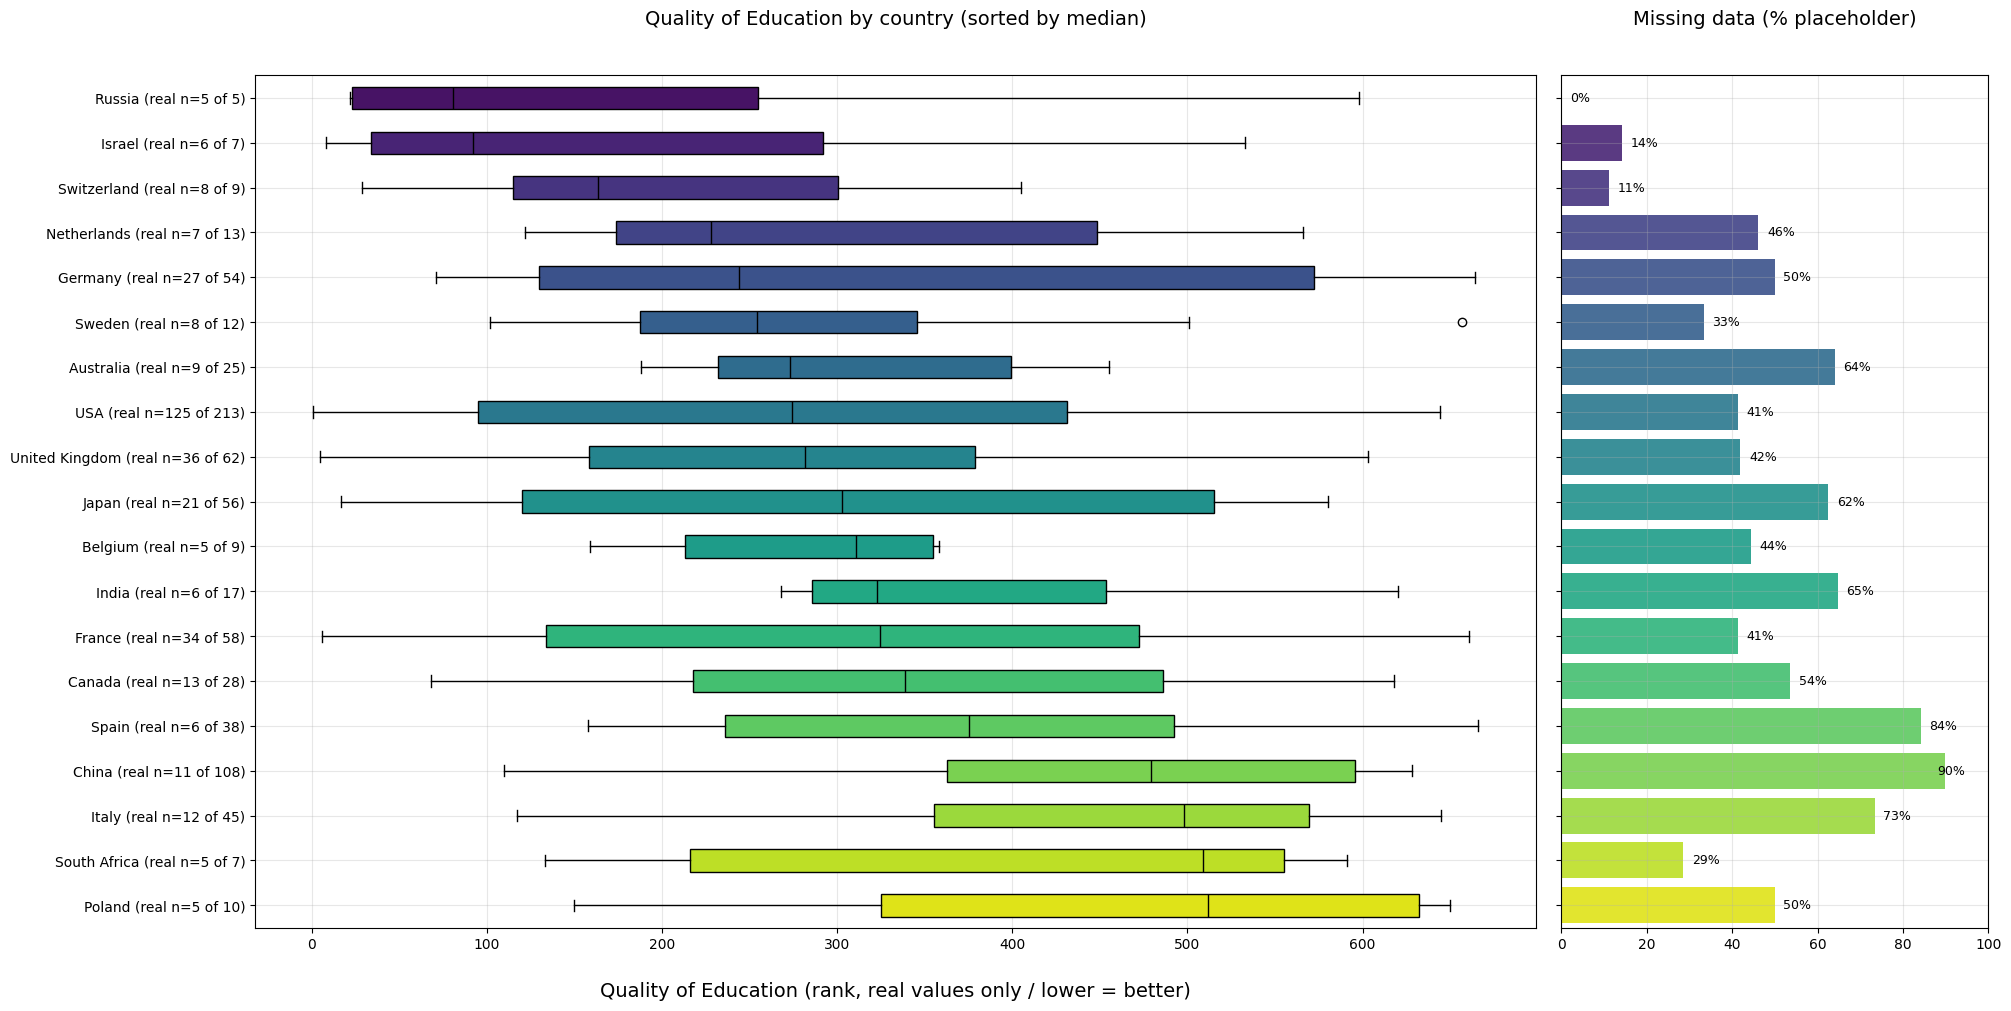

In [62]:
real = Data_Cleaned[Data_Cleaned["Quality of Education_was_placeholder"] == 0]

n_total = Data_Cleaned["Location"].value_counts()
n_real = real["Location"].value_counts()
median_qoe = real.groupby("Location")["Quality of Education"].median()

table = pd.DataFrame({"n_total": n_total, "n_real": n_real, "median": median_qoe})
table["n_real"] = table["n_real"].fillna(0).astype(int)            
table["pct_placeholder"] = 100 - table["n_real"] / table["n_total"] * 100

ok = table[table["n_real"] >= 5].sort_values("median")

data = []
labels = []
for country in ok.index:
    data.append(real[real["Location"] == country]["Quality of Education"])
    labels.append(country + " (real n=" + str(ok.loc[country, "n_real"]) + " of " + str(ok.loc[country, "n_total"]) + ")")

fig, (ax1, ax2) = plt.subplots(
    1, 2, 
    figsize=(20, 10), 
    sharey=True,
    gridspec_kw={"width_ratios": [3, 1]}, 
    layout="constrained"
    )

bp = ax1.boxplot(
    data,
    vert=False,
    patch_artist=True,
    medianprops={"color": "black"}
)

colors = sns.color_palette("viridis", n_colors=len(labels))
for box, color in zip(bp["boxes"], colors):
    box.set_facecolor(color)

ax1.set_yticks(range(1, len(labels) + 1))
ax1.set_yticklabels(labels)
ax1.invert_yaxis()                                                 
ax1.set_xlabel(
    "Quality of Education (rank, real values only / lower = better)",
    fontsize=14,
    labelpad=22
    )
ax1.set_title(
    "Quality of Education by country (sorted by median)",
    fontsize=14,
    y=1.05
    )
ax1.grid(True, alpha=0.3)

ax2.barh(range(1, len(labels) + 1), ok["pct_placeholder"], color=colors, alpha=0.9)
ax2.set_xlim(0, 100)
ax2.set_title(
    "Missing data (% placeholder)",
    fontsize=14,
    y=1.05
    )
ax2.grid(True, alpha=0.3)

for i in range(len(ok)):
    v = ok["pct_placeholder"].iloc[i]
    ax2.text(min(v + 2, 88), i + 1, str(round(v)) + "%", va="center", fontsize=9)

plt.show()

> #### **NOTE**
>> #### This plot is intended to provide a deeper understanding of the previous heatmap, allowing for a better view of both the extent of the overlaps and the medians.
>> #### Since the "Quality of Education" metric has approximately 60% placeholder values, we use only the actual values ​​(flag = 0). Each country is labeled with its "real n" (the number of actual data points out of its total universities), and the right-hand column shows the percentage of placeholder values ​​for that country. The countries are sorted by median rank, with the best-performing ones at the top (lower rank = better).
>> #### Countries are sorted by median rank, with the best-performing ones at the top (lower rank = better).
>> #### This comparison is limited to universities that reported this metric. China is represented by only 11 universities out of 108, so this does not reflect the full picture of Chinese universities.
>> #### The left-hand column displays the percentage of placeholder data used by each university and next to each country's name, the number of actual data points (real n) is shown relative to the total data for that country.

> #### ●. Only 19 out of the 61 countries have at least five actual values. Notable countries that were excluded include South Korea (1 out of 35), Brazil (3 out of 20), Taiwan (4 out of 17), Turkey (2 out of 13), Iran (2 out of 12), and Austria (4 out of 11).
> #### ●. Countries where the median is based on only a few universities,such as Russia (median 81 - 5 universities), Israel (92 - 6 universities) and Switzerland (163.5 - 8 universities), should not be taken too seriously. In contrast, Germany (244 - 27 universities), the US (274 - 125 universities) and the UK (281.5 - 36 universities) are more reliable, as they are based on larger sample sizes.
> #### ●. The relationship between the placeholder percentage and the median is not uniform. China (90%), Italy (73%) and Spain (84%) have high placeholder rates and worse medians, whereas Australia (64%) and Japan (62%) despite having high placeholder rates—maintain relatively good medians. Therefore, one cannot simply say that "any country with a higher rate of missing data is weaker".
> #### ●. The variation within each country is far greater than the variation between countries. The United States, after that France and the United Kingdom, are roughly between 0-610. On the other hand, most of the country boxes overlap, meaning that "location" alone is a poor predictor of the quality of a university's education.

> ## **3.9.** Comparison of score distribution differences

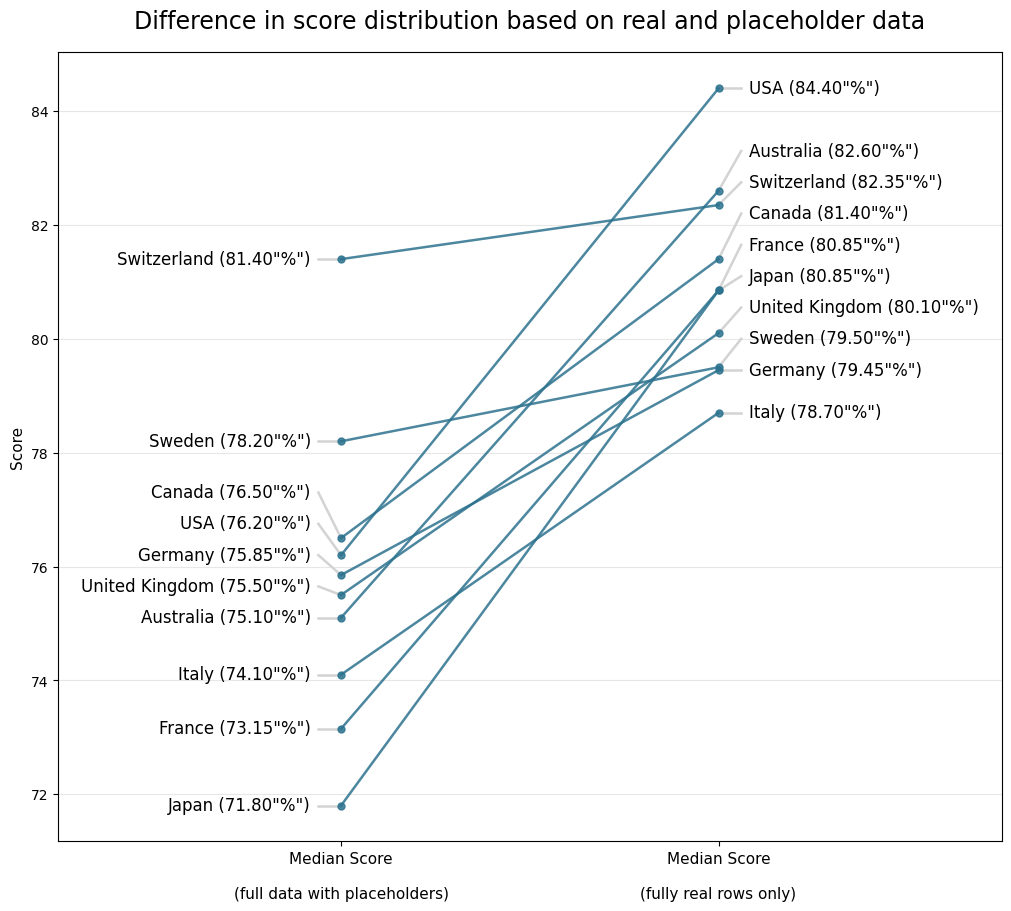

In [63]:
flag_cols = [c for c in Data_Cleaned.columns if c.endswith("_was_placeholder")]
fully_real = Data_Cleaned[(Data_Cleaned[flag_cols] == 0).all(axis=1)]

n_real = fully_real["Location"].value_counts()
countries = n_real[n_real >= 5].index.tolist()

full_medians = {c: Data_Cleaned[Data_Cleaned["Location"] == c]["Score"].median() for c in countries}
real_medians = {c: fully_real[fully_real["Location"] == c]["Score"].median() for c in countries}

df = pd.DataFrame({
    "Country": countries,
    "median_full": [full_medians[c] for c in countries],
    "median_real": [real_medians[c] for c in countries],
})
df["change"] = df["median_real"] - df["median_full"]

def spread_labels(values, min_gap):
    order = sorted(range(len(values)), key=lambda i: values[i])
    adjusted = list(values)
    for k in range(1, len(order)):
        i, prev = order[k], order[k - 1]
        if adjusted[i] - adjusted[prev] < min_gap:
            adjusted[i] = adjusted[prev] + min_gap
    return adjusted

left_y = spread_labels(df.sort_values("median_full")["median_full"].tolist(), 0.55)
df_left = df.sort_values("median_full").copy()
df_left["label_y_left"] = left_y

right_y = spread_labels(df.sort_values("median_real")["median_real"].tolist(), 0.55)
df_right = df.sort_values("median_real").copy()
df_right["label_y_right"] = right_y

df = df.merge(df_left[["Country", "label_y_left"]], on="Country")
df = df.merge(df_right[["Country", "label_y_right"]], on="Country")
df = df.sort_values("median_full", ascending=False)

fig, ax = plt.subplots(figsize=(10, 9), layout="constrained")
x_left, x_right = 0, 1

for _, row in df.iterrows():
    color = palette[2] if row["change"] > 0 else ("tab:red" if row["change"] < 0 else "gray")
    ax.plot([x_left, x_right], [row["median_full"], row["median_real"]],
            color=color, marker="o", markersize=5, linewidth=1.8, alpha=0.85, zorder=2)
    ax.plot([x_left - 0.06, x_left], [row["label_y_left"], row["median_full"]],
            color="lightgray", linewidth=1.8, zorder=1)
    ax.plot([x_right, x_right + 0.06], [row["median_real"], row["label_y_right"]],
            color="lightgray", linewidth=1.8, zorder=1)
    ax.text(x_left - 0.08, row["label_y_left"], f'{row["Country"]} ({row["median_full"]:.2f}"%")',
            ha="right", va="center", fontsize=12)
    ax.text(x_right + 0.08, row["label_y_right"], f'{row["Country"]} ({row["median_real"]:.2f}"%")',
            ha="left", va="center", fontsize=12)

ax.set_xlim(-0.75, 1.75)
ax.set_xticks([x_left, x_right])
ax.set_xticklabels(
    ["Median Score\n\n(full data with placeholders)", 
     "Median Score\n\n(fully real rows only)"],
     fontsize=11
     )

ax.set_ylabel("Score", fontsize=11)
ax.set_title(
    "Difference in score distribution based on real and placeholder data", 
    fontsize=17,
    y=1.02
    )

ax.grid(True, axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.show()

> #### **NOTE**
>> #### Only countries that have at least five universities within a proper subset (with no flags across any of the seven attributes) have been selected for analysis.
>> #### The difference in scores between countries may be partly real and partly due to placeholder.

> #### It is visually evident and certain that the lines slope upwards, without exception. This means that removing the placeholder always raises the median and always pulls down the score.
> #### The slopes are not the same. Japan, USA and then Australia suffered the most "damage" from placeholders, but Switzerland and Sweden remained almost untouched.
> #### The ranking of the countries changes. In the left column, Switzerland is at the top, while in the right column, USA overtakes Switzerland.

In [64]:
countries = n_real[n_real >= 5].index.tolist()
full_medians = {c: Data_Cleaned[Data_Cleaned["Location"] == c]["Score"].median() for c in countries}
real_medians = {c: fully_real[fully_real["Location"] == c]["Score"].median() for c in countries}

table = pd.DataFrame({
    "Country": countries,
    "n_full": [len(Data_Cleaned[Data_Cleaned["Location"] == c]) for c in countries],
    "median_full_data": [round(full_medians[c], 1) for c in countries],
    "n_fully_real": [len(fully_real[fully_real["Location"] == c]) for c in countries],
    "median_fully_real": [round(real_medians[c], 1) for c in countries],
})
table["rank_full"] = table["median_full_data"].rank(ascending=False).astype(int)
table["rank_real"] = table["median_fully_real"].rank(ascending=False).astype(int)
table["rank_change"] = table["rank_full"] - table["rank_real"]
table = table.sort_values("rank_real")

table

,Country,n_full,median_full_data,n_fully_real,median_fully_real,rank_full,rank_real,rank_change
0,USA,213,76.2,61,84.4,4,1,3
7,Australia,25,75.1,6,82.6,7,2,5
5,Switzerland,9,81.4,6,82.4,1,3,-2
4,Canada,28,76.5,8,81.4,3,4,-1
3,Japan,56,71.8,8,80.8,10,5,5
6,France,58,73.2,6,80.8,9,5,4
1,United Kingdom,62,75.5,21,80.1,6,7,-1
8,Sweden,12,78.2,5,79.5,2,8,-6
2,Germany,54,75.8,14,79.4,5,9,-4
9,Italy,45,74.1,5,78.7,8,10,-2


> #### ●. The United States rose from 4th to 1st place, while Japan and France also climbed four to five spots. In contrast, Sweden fell from 2nd to 8th place.
> #### ●. he ranking of countries based on the score was highly sensitive to whether or not placeholders were included in the calculation. Part of the score difference between countries (observed in the previous chart) was actually an artifact of differing missingness patterns, rather than simply reflecting the true quality of the universities.
> #### ●. The difference in medians is relatively small. In other words—contrary to what one might expect—most countries with a large number of universities have similar score medians (mostly ranging between 72 and 76).
> #### ●. Despite the low median, Japan has a few exceptions at the very top.

> ## **3.10.** Number of universities and world ranking

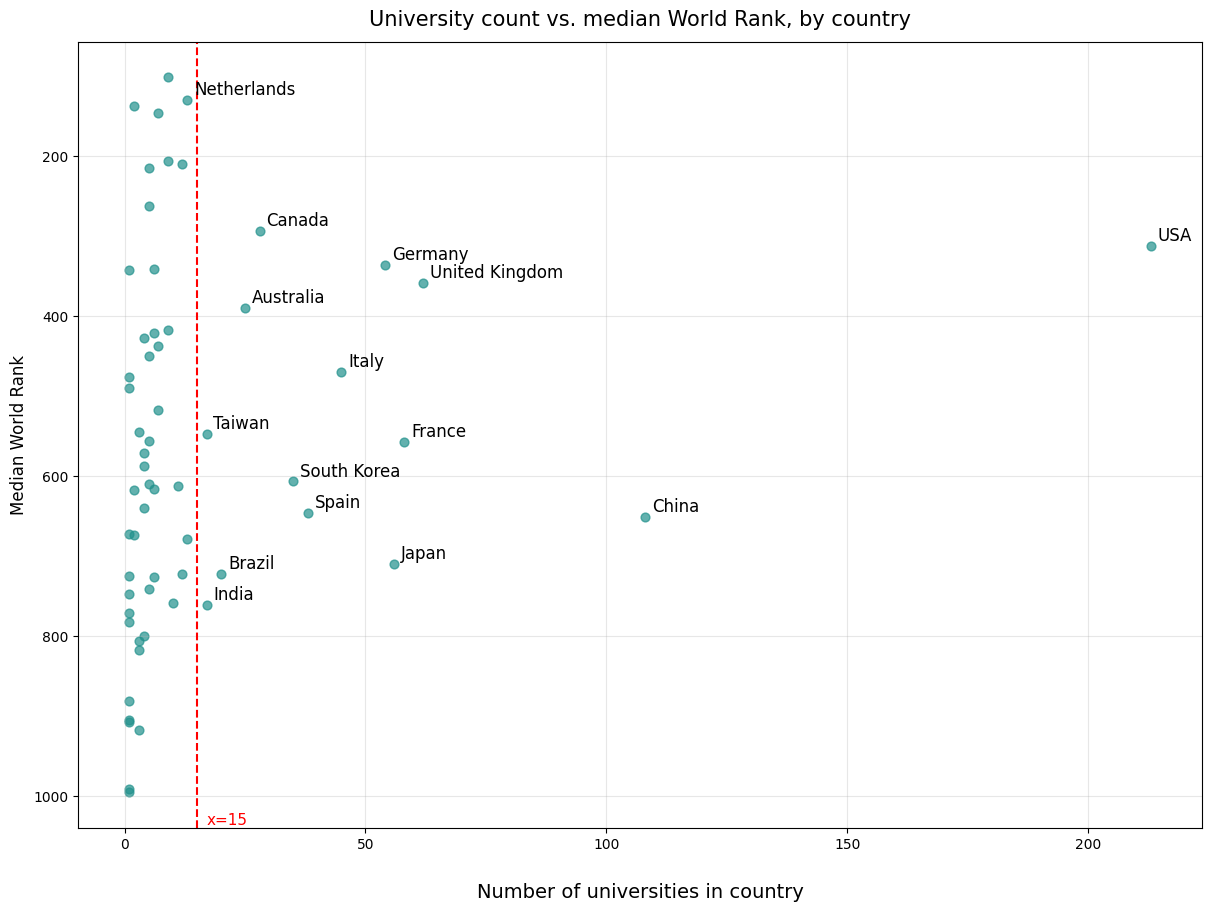

In [65]:
agg = Data_Cleaned.groupby("Location").agg(
    n=("Institution", "count"),
    median_world_rank=("World Rank", "median"),
).reset_index()

fig, ax = plt.subplots(figsize=(12, 9), layout="constrained")
ax.scatter(agg["n"], agg["median_world_rank"], s=40, alpha=0.7, color=palette[3])


ax.axvline(x=15, color="red", linestyle="--", linewidth=1.5)
ax.text(17, ax.get_ylim()[1], "x=15", color="red", fontsize=11,
        ha="left", va="bottom", rotation=0,
        transform=ax.transData)

top = agg.sort_values("n", ascending=False).head(15)
for _, row in top.iterrows():
    ax.annotate(row["Location"], (row["n"], row["median_world_rank"]),
                fontsize=12, xytext=(5, 4), textcoords="offset points")

ax.invert_yaxis() 
ax.set_xlabel(
    "Number of universities in country", 
    labelpad=22,
    fontsize= 14
    )

ax.set_ylabel("Median World Rank", fontsize=12)

ax.set_title(
    "University count vs. median World Rank, by country", 
    fontsize=15,
    y=1.01
    )

ax.grid(True, alpha=0.3)

plt.show()

> #### **NOTE** 
>> #### Turkey and the Netherlands both have an equal number of universities.
>> #### The more universities a country has, the better its average ranking becomes, not worse.
>> #### Lower rank = better. So, being higher on the graph means a better rank.
>> #### We used "World Rank" instead of "Score" because it never has a placeholder.

> #### ●. The majority of the chart is concentrated in that narrow strip on the left (approximately n < 15).
> #### ●. These 15 countries have the highest number of universities.
> #### ●. The large number of these countries are clustered mainly in the middle of the chart, but one cannot claim this represents an absolute relationship; for instance, China, with 108 universities, has a median ranking of around 650, whereas Japan, with 56 universities, sits at approximately 700.
> #### ●. Countries with fewer universities (on the left, x=15) are scattered across the entire y-axis—ranging from very good to very poor rankings—and no discernible pattern emerges.
> #### ●. The overall correlation stems primarily from the small countries below x = 15, rather than from a few large countries.

> ## **3.11.** A unified visual display of data on a world map

In [66]:
font1 = {"color": "black", "size": 20, "weight": "bold"}

stats = Data_Cleaned.groupby("Location").agg(
    **{"University Count": ("Institution", "count"),
       "Avg Rank": ("World Rank", "mean"),
       "Avg Score": ("Score", "mean")}
).reset_index()

best_idx = Data_Cleaned.groupby("Location")["World Rank"].idxmin()
best = Data_Cleaned.loc[best_idx, ["Location", "Institution", "World Rank", "National Rank"]]
best = best.rename(columns={"Institution": "Best University",
                            "World Rank": "Best World Rank",
                            "National Rank": "Best National Rank"})
stats = stats.merge(best, on="Location")

n_stops = 7
palette = sns.color_palette("viridis", n_colors=n_stops)
palette_hex = [f"#{int(r*255):02x}{int(g*255):02x}{int(b*255):02x}" for r, g, b in palette]
positions = [i / (n_stops - 1) for i in range(n_stops)]
custom_scale = list(zip(positions, palette_hex))

fig = px.choropleth(
    stats,
    locations="Location",
    locationmode="country names",
    color="University Count",
    hover_name="Location",
    custom_data=["University Count", "Avg Rank", "Avg Score",
                 "Best University", "Best World Rank", "Best National Rank"],
    color_continuous_scale=custom_scale,
    range_color=[stats["University Count"].min(), stats["University Count"].max()],
)

fig.update_traces(hovertemplate=(
    "<b>%{hovertext}</b><br><br>"
    "Universities: %{customdata[0]}<br>"
    "Average world rank: %{customdata[1]:.0f}<br>"
    "Average score: %{customdata[2]:.2f}%<br>"
    "Best university: %{customdata[3]}<br>"
    "Best world rank: %{customdata[4]:.0f}<br>"
    "Best national rank: %{customdata[5]:.0f}"
    "<extra></extra>"))

fig.update_geos(
    projection_type="orthographic",
    projection_rotation=dict(lon=20, lat=30),
    projection_scale=1,
    showframe=False,
    showcoastlines=True, coastlinecolor="black",
    showcountries=True, countrycolor="white",
    showland=True, landcolor="#F5F5F5",
    showocean=True, oceancolor="#D9EEF7",
)

def metric_button(label, col, reverse):
    v = stats[col]
    return dict(
        label=label, method="update",
        args=[{"z": [v.tolist()]},
              {"coloraxis.cmin": float(v.min()), "coloraxis.cmax": float(v.max()),
               "coloraxis.reversescale": reverse,
               "coloraxis.colorbar.title.text": label.replace(" ", "<br>", 1)}],
    )

def zoom_button(s):
    return dict(label=f"{s}x", method="relayout", args=[{"geo.projection.scale": s}])

menu_style = dict(type="buttons", direction="right", showactive=True,
                  bgcolor="white", bordercolor="gray", pad=dict(l=4, r=4, t=4, b=4))

fig.update_layout(
    height=850,
    title={"text": "Number of Universities in Ranking by Country",
           "x": 0.5, "xanchor": "center", "font": font1},
    coloraxis_colorbar={
        "orientation": "h", "x": 0.5, "xanchor": "center",
        "y": 1.02, "yanchor": "bottom", "len": 0.65, "thickness": 10,
        "title": {"text": "University<br>Count", "font": {"color": "black", "size": 16, "weight": "bold"}},
        "tickfont": {"color": "black", "size": 15, "weight": "bold"},
    },
    updatemenus=[
        dict(menu_style, x=0.0, y=0.02, xanchor="left", yanchor="bottom", buttons=[
            metric_button("University Count", "University Count", False),
            metric_button("Average Score", "Avg Score", False),
            metric_button("Average Rank", "Avg Rank", True),
        ]),
        dict(menu_style, x=1.0, y=0.02, xanchor="right", yanchor="bottom",
             buttons=[zoom_button(s) for s in (1, 1.5, 2, 3)]),
    ],
    margin=dict(l=0, r=0, t=100, b=0),
)

fig.show(config={"scrollZoom": True, "displaylogo": False})

> ## **3.12.** Comparing the distribution of features and placeholder pattern of the Top 100 vs all data

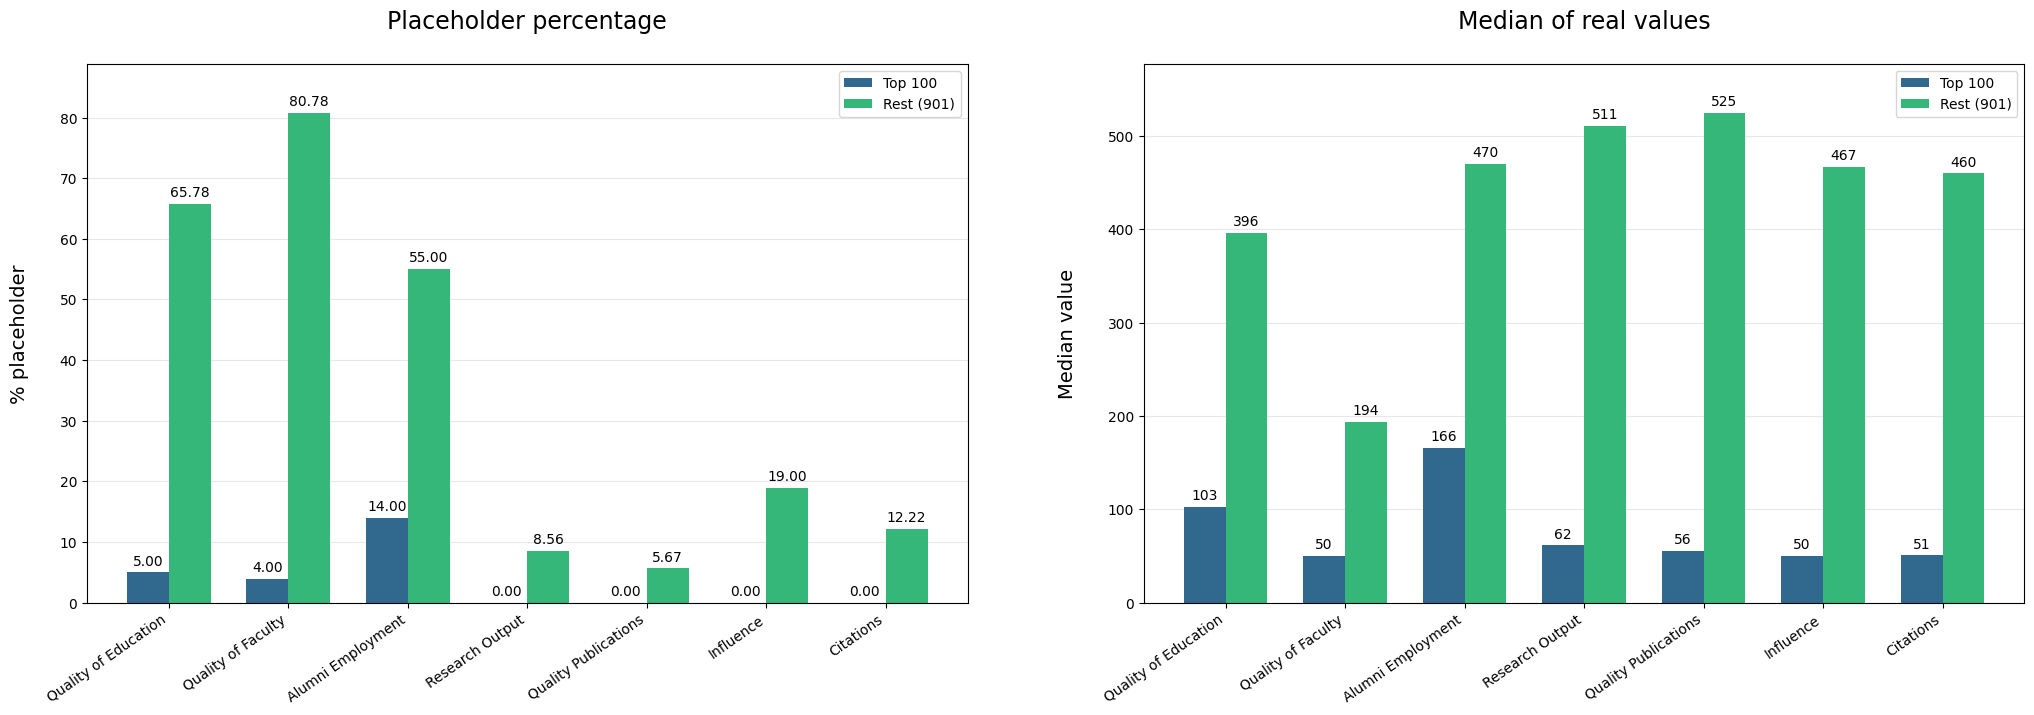

In [67]:
palette = sns.color_palette("viridis", n_colors=2)

Data_Cleaned["group"] = np.where(Data_Cleaned["World Rank"] <= 100, "Top 100", "Rest (901)")

pct_top = [(Data_Cleaned[Data_Cleaned["group"]=="Top 100"][c+"_was_placeholder"]==1).mean()*100 for c in cols]
pct_rest = [(Data_Cleaned[Data_Cleaned["group"]=="Rest (901)"][c+"_was_placeholder"]==1).mean()*100 for c in cols]

med_top, med_rest = [], []
for c in cols:
    real = Data_Cleaned[Data_Cleaned[c+"_was_placeholder"]==0]
    med_top.append(real[real["group"]=="Top 100"][c].median())
    med_rest.append(real[real["group"]=="Rest (901)"][c].median())

x = np.arange(len(cols))
w = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(25, 7))
plt.subplots_adjust(wspace=0.2)

bars1 = ax1.bar(x - w/2, pct_top, width=w, label="Top 100", color=palette[0])
bars2 = ax1.bar(x + w/2, pct_rest, width=w, label="Rest (901)", color=palette[1])
ax1.bar_label(bars1, fmt="%.2f", padding=3)
ax1.bar_label(bars2, fmt="%.2f", padding=3)
ax1.set_xticks(x)

ax1.set_xticklabels(cols, rotation=35, ha="right")
ax1.set_ylabel("% placeholder", fontsize=14, labelpad=22)
ax1.set_title("Placeholder percentage", fontsize=17, y=1.05)

ax1.margins(y=0.1)
ax1.grid(axis="y", alpha=0.3)
ax1.set_axisbelow(True)
ax1.legend()


bars3 = ax2.bar(x - w/2, med_top, width=w, label="Top 100", color=palette[0])
bars4 = ax2.bar(x + w/2, med_rest, width=w, label="Rest (901)", color=palette[1])
ax2.bar_label(bars3, fmt="%.0f", padding=3)
ax2.bar_label(bars4, fmt="%.0f", padding=3)
ax2.set_xticks(x)

ax2.set_xticklabels(cols, rotation=35, ha="right")
ax2.set_ylabel("Median value", fontsize=14, labelpad=22)
ax2.set_title("Median of real values", fontsize=17, y=1.05)

ax2.margins(y=0.1)
ax2.grid(axis="y", alpha=0.3)
ax2.set_axisbelow(True)
ax2.legend()


plt.show()

> #### **NOTE**
>> #### For calculate median calues, just used of real rows only / lower = better

> #### ●. Regarding the research cluster:
>> #### (Research Output, Quality Publications): The Top 100 group has virtually zero percent missing data (placeholders), whereas other universities range from 5.7% to 8.6%.
>> #### Quality of Faculty: The gap is stark; the Top 100 group has only 4% missing data, compared to 80.8% for the rest.
> #### ●. Top global universities (Harvard, Stanford, MIT, etc.) generally possess greater resources and transparency for fully reporting metrics, whereas smaller or lesser-known universities are more prone to data gaps.
> #### ●. The Top 100 group shows significant overlap with the "universities that report complete data."

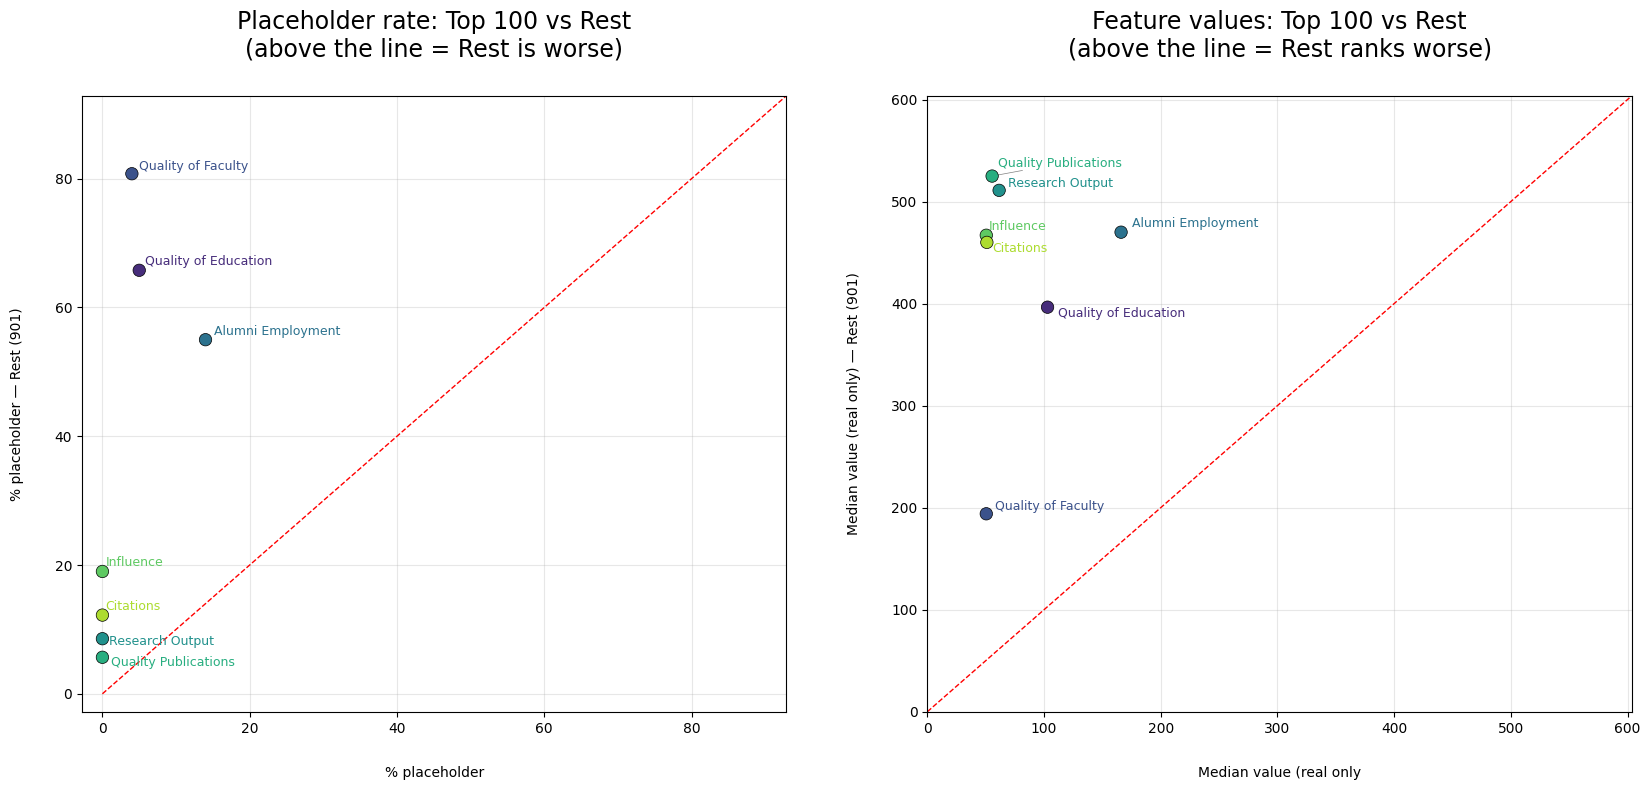

In [68]:
palette = sns.color_palette("viridis", n_colors=len(cols))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
plt.subplots_adjust(wspace=0.2)


lim1 = max(pct_top + pct_rest) * 1.15
margin1 = lim1 * 0.03
ax1.plot([0, lim1], [0, lim1], color="red", linestyle="--", linewidth=1)
ax1.scatter(pct_top, pct_rest, s=80, color=palette, edgecolor="black", linewidth=0.5, zorder=3)

texts1 = []
for i, c in enumerate(cols):
    texts1.append(ax1.text(pct_top[i], pct_rest[i], c, fontsize=9, color=palette[i]))
adjust_text(texts1, ax=ax1, arrowprops=dict(arrowstyle="-", color="black", lw=0.5))

ax1.set_xlabel("% placeholder", labelpad=22)
ax1.set_ylabel("% placeholder — Rest (901)", labelpad=22)
ax1.set_title("Placeholder rate: Top 100 vs Rest\n(above the line = Rest is worse)", fontsize=17, y=1.05)
ax1.set_xlim(-margin1, lim1)
ax1.set_ylim(-margin1, lim1)

ax1.grid(True, alpha=0.3)


lim2 = max(med_top + med_rest) * 1.15
ax2.plot([0, lim2], [0, lim2], color="red", linestyle="--", linewidth=1)
ax2.scatter(med_top, med_rest, s=80, color=palette, edgecolor="black", linewidth=0.5, zorder=3)

texts2 = []
for i, c in enumerate(cols):
    texts2.append(ax2.text(med_top[i], med_rest[i], c, fontsize=9, color=palette[i]))
adjust_text(texts2, ax=ax2, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))

ax2.set_xlabel("Median value (real only", labelpad=22)
ax2.set_ylabel("Median value (real only) — Rest (901)", labelpad=22)
ax2.set_title("Feature values: Top 100 vs Rest\n(above the line = Rest ranks worse)", fontsize=17, y=1.05)
ax2.set_xlim(0, lim2)
ax2.set_ylim(0, lim2)

ax2.grid(True, alpha=0.3)

plt.show()

> #### **NOTE**
>> #### X-axis: Top 100 value – Y-axis: Rest value – Diagonal gray line: "No difference"

> #### ●. In the left panel (placeholder), the features are very clearly divided into two clusters, three (Quality of Faculty, Quality of Education, Alumni Employment) are very high up the line and the other four (Research Cluster) are almost stuck to the bottom left corner, close to zero (zero means both the Top 100 and the rest are low placeholders).

> ## **3.13.** National distribution of the Top 100 vs. national distribution of the entire dataset.

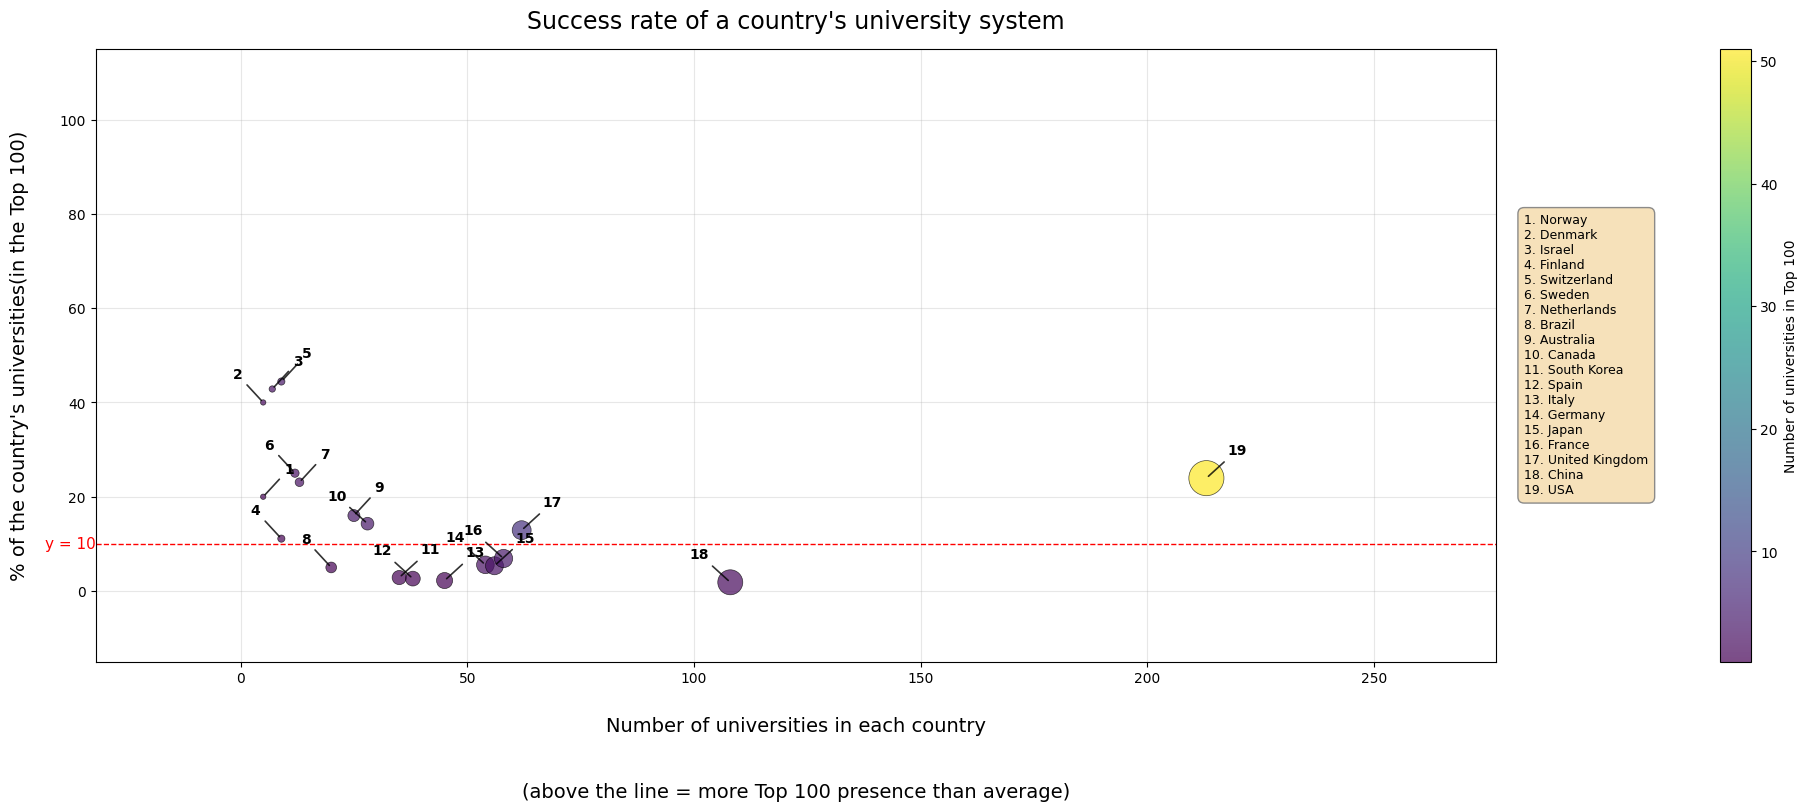

In [69]:
top100 = Data_Cleaned[Data_Cleaned["World Rank"] <= 100]
n_top, n_full = len(top100), len(Data_Cleaned)

top_counts = top100["Location"].value_counts()
full_counts = Data_Cleaned["Location"].value_counts()
countries = top_counts.index.tolist()

table = pd.DataFrame({
    "country": countries,
    "n_top100": [top_counts[c] for c in countries],
    "n_full": [full_counts[c] for c in countries],
})

table["pct_in_top100"] = table["n_top100"] / table["n_full"] * 100

grouped = (
    table.groupby(["n_full", "pct_in_top100", "n_top100"])["country"]
    .apply(lambda s: "\n".join(s))
    .reset_index()
)

baseline = n_top / n_full * 100

fig, ax = plt.subplots(figsize=(18, 8), layout="constrained")

ax.axhline(
    10,
    color="red",
    linestyle="--",
    linewidth=1,
    label="y = 10"
)

sc = ax.scatter(
    grouped["n_full"],
    grouped["pct_in_top100"],
    s=grouped["n_full"] * 3,
    c=grouped["n_top100"],
    cmap="viridis",
    edgecolor="black",
    linewidth=0.5,
    zorder=3,
    alpha=0.7
)


cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Number of universities in Top 100")


for i, (_, row) in enumerate(grouped.iterrows(), start=1):

    if i % 2 == 1:
        x_offset = 15
        ha = "left"
    else:
        x_offset = -15
        ha = "right"

    y_offset = 15

    ax.annotate(
        str(i),
        xy=(row["n_full"], row["pct_in_top100"]),
        xytext=(x_offset, y_offset),
        textcoords="offset points",
        fontsize=10,
        ha=ha,
        va="bottom",
        fontweight="bold",
        color="black",
        arrowprops=dict(
            arrowstyle="-",
            color="black",
            lw=1.2,
            alpha=0.8
        )
    )

legend_text = "\n".join(
    [
        f"{i}. {row['country']}"
        for i, (_, row) in enumerate(grouped.iterrows(), start=1)
    ]
)

ax.text(
    1.02,
    0.5,
    legend_text,
    transform=ax.transAxes,
    fontsize=9,
    va="center",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="wheat",
        edgecolor="gray",
        alpha=0.9
    )
)


ax.set_xlabel(
    "Number of universities in each country\n\n\n"
    "(above the line = more Top 100 presence than average)",
    fontsize=14,
    labelpad=22
)

ax.set_ylabel(
    "% of the country's universities(in the Top 100)",
    fontsize=14,
    labelpad=22
)

ax.set_title(
    "Success rate of a country's university system",
    fontsize=17,
    y=1.02
)

x_margin = table["n_full"].max() * 0.15
y_margin = max(table["pct_in_top100"].max() * 0.15, 15)

ax.set_xlim(
    -x_margin,
    table["n_full"].max() * 1.15 + x_margin
)

ax.set_ylim(
    -y_margin,
    max(table["pct_in_top100"].max() * 1.2, 100) + y_margin
)


ax.text(
    ax.get_xlim()[0],
    10,
    "y = 10",
    color="red",
    fontsize=11,
    ha="right",
    va="center",
    transform=ax.transData
)


ax.grid(True, alpha=0.3)

plt.show()

> #### **NOTE**
>> #### y = 10 is a completely hypothetical and random range, drawn just for better visibility.

> #### ●. Only 19 out of 61 countries have even a single university in the top 100; this means 42 countries have no representation in the top 100.
> #### ●. The United States exhibits the most extreme over-representation. It is the only country that shows both a large "bubble" and a position clearly above the reference line, followed by the United Kingdom.
> #### ●. Dominance in this dataset is heavily concentrated among a few Western nations—or small, high-quality ones—since the very countries showing over-representation (the US, the UK, and Switzerland) were precisely those with the fewest "placeholders."
> #### ●. The chart clearly demonstrates that a large number of universities does not necessarily equate to a higher success rate. There are smaller countries that, despite having more limited educational systems, have achieved significantly higher output and a greater share of quality relative to the total number of their universities.

> ## **3.14.** Grouping based on reporting completeness

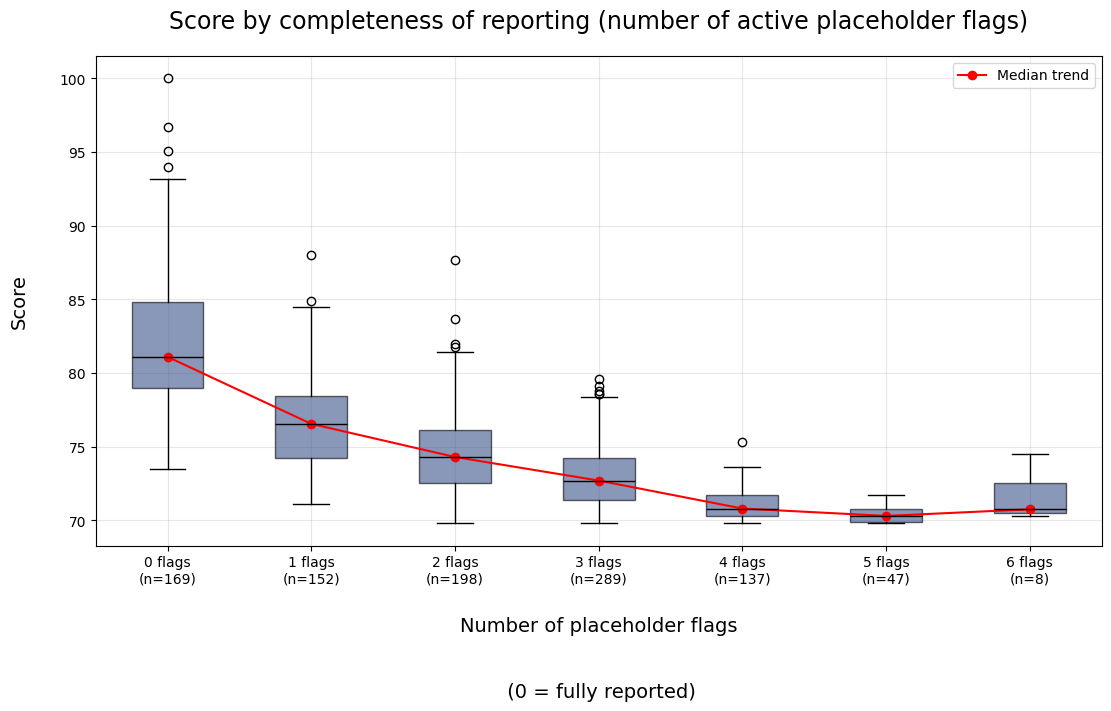

In [70]:
flag_cols = [c for c in Data_Cleaned.columns if c.endswith("_was_placeholder")]
Data_Cleaned["num_flags"] = Data_Cleaned[flag_cols].sum(axis=1) 

groups = sorted(Data_Cleaned["num_flags"].unique())
data = [Data_Cleaned[Data_Cleaned["num_flags"] == g]["Score"] for g in groups]
labels = [f"{g} flags\n(n={len(d)})" for g, d in zip(groups, data)]

fig, ax = plt.subplots(figsize=(11, 7), layout="constrained")
bp = ax.boxplot(data, patch_artist=True, medianprops={"color": "black"})
for box in bp["boxes"]:
    box.set_facecolor(palette[1])
    box.set_alpha(0.6)

medians = [d.median() for d in data]
ax.plot(range(1, len(groups) + 1), medians, color="red", marker="o", linewidth=1.5, label="Median trend")

ax.set_xticks(range(1, len(groups) + 1))
ax.set_xticklabels(labels)

ax.set_xlabel("Number of placeholder flags\n\n\n"
" (0 = fully reported)",
fontsize=14, labelpad=22
)

ax.set_ylabel("Score", fontsize=14, labelpad=22)
ax.set_title("Score by completeness of reporting (number of active placeholder flags)", fontsize=17, y=1.04)
ax.grid(True, alpha=0.3)
ax.set_axisbelow(True)
ax.legend()

plt.show()

> #### ●. There is a very strong and nearly monotonic relationship. It is one of the strongest relationships observed in the entire project—even stronger than the correlation between some key features and the Score.
> #### ●. The median drops consistently: from 81 (0 flags) to 74.3 (2 flags), 73 (3 flags), and a floor near 71 (5 flags). This means each additional flag systematically lowers the Score.
> #### ●. Dispersion also decreases as the number of flags rises. The "0 flags" box is tall and wide (large IQR, ranging from 79 to 85, with an outlier at 100), whereas the "5 flags" box is very narrow. Universities that report very little data almost all have Scores near the floor (70). This makes sense: the Score floor is always around 70 (since the score is defined on a limited scale), so the weaker the university and the less data it reports, the closer it sits to this floor.
> #### ●. The "6 flags" group (comprising only 8 universities) is a minor exception. Its median (71) is slightly higher than that of the "5 flags" group (70), bucking the downward trend. However, with a sample size of only 8 universities, this could simply be statistical noise rather than a genuine pattern.
> #### ●. No university has "7 flags" (meaning all data is missing); there is always at least one actual feature present.

# 4) Concolusion

>> ### Flags themselves can serve as a powerful, independent feature for the model.
>> ### Keep the flags; they carry a strong, genuine signal.
>> ### Exclude "World Rank" and "National Rank" from the model features.
>> ### Manage multicollinearity regarding the research cluster.
>> ### Use "Citations" with caution.
>> ### "Location" is a useful feature but is confounded with reporting completeness.



### **Ultimately, this exploratory data analysis provides an overview of the data structure, the relationships between ranking indicators and factors associated with placeholders, and their role in the rankings of universities and countries. However, data analysis is a continuous, multi-layered process that requires an understanding of the data and the objectives of the analysis; more precise results can always be achieved through further, in-depth examination.**